# Analisis Dampak Variasi Cuaca (Suhu & Curah Hujan) terhadap Tren Hunian Hotel
### Studi kasus: 38 provinsi Indonesia, dengan **Provinsi Bali** sebagai sorotan

Notebook ini memuat seluruh tahap akuisisi data dalam satu berkas Colab:

| Bagian | Isi |
|---|---|
| 1 | Ingesti file BPS, profil data, estimasi storage 1 tahun |
| 2 | Audit lisensi, audit PII/quasi-identifier, Data Ethics Checklist (9 butir) |
| 3 | Akuisisi API Open-Meteo (JSON → DataFrame) |
| 4 | Web scraping etis (Wikipedia, dengan cek `robots.txt`) |
| 5 | Penggabungan data (`pd.merge` + `validate`) dan catatan provenance (MD5) |
| 6 | (Opsional) Eksplorasi awal hubungan cuaca–hunian |

**Sumber data**

1. **File BPS** (terstruktur, CSV): Tingkat Penghunian Kamar (TPK) Hotel Bintang 2026, Jumlah Akomodasi/Kamar/Tempat Tidur Hotel Nonbintang 2025, Penerimaan dari Wisman 2014.
2. **API Open-Meteo** (semi-terstruktur, JSON): suhu maksimum & curah hujan harian.
3. **Web scraping** (tabel HTML): daftar provinsi dari Wikipedia Indonesia.

---
### Catatan desain (baca dulu)

* **Syarat ≥100 baris.** Ketiga CSV yang diunggah berformat tabel BPS "lebar" dan masing-masing hanya 38–41 baris. File TPK menjadi **38 provinsi × 9 bulan (Jan–Sep 2026) = 342 baris** setelah diubah ke format panjang (*tidy*). Karena itu cakupan analisis adalah **seluruh provinsi**, dan Bali menjadi studi kasus. Jika hanya Bali yang dipakai, datanya cuma 9 baris.
* **Data cuaca** diambil satu titik per provinsi (koordinat ibu kota provinsi) sebagai *proxy* cuaca provinsi. Ini keterbatasan yang dicatat di Bagian 2 dan 6.
* **File Wisman 2014** bersifat nasional, per negara asal, dan tahunan. Datanya tidak bisa digabung dengan cuaca provinsi bulanan 2026. File ini tetap di-ingest, diprofilkan, diaudit, dan dicatat provenance-nya, tetapi **tidak masuk ke merge**.
* **File Nonbintang 2025** dipakai sebagai atribut kapasitas per provinsi (relasi *many-to-one* ke panel provinsi–bulan).

## 0. Setup & Identitas
Ganti identitas di bawah ini **sebelum** menjalankan Bagian 3 dan 4. `User-Agent` akan dikirim ke server Open-Meteo dan Wikipedia agar pengelola situs bisa menghubungi Anda bila ada masalah.

In [3]:
import hashlib, io, json, re, shutil, sys, time
from datetime import datetime
from pathlib import Path
from urllib import robotparser
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)

# ============ IDENTITAS (WAJIB DIGANTI) ============
NAMA = "Kadek satya giri sardhula"
NIM = "2501010088"
EMAIL_KAMPUS = "mahasiswa@instiki.ac.id"
# ===================================================

USER_AGENT = (f"TugasAkuisisiData/1.0 ({NAMA}; NIM {NIM}; kontak: {EMAIL_KAMPUS}; "
              "keperluan akademik non-komersial)")
HEADERS_JSON = {"User-Agent": USER_AGENT, "Accept": "application/json"}
HEADERS_HTML = {"User-Agent": USER_AGENT, "Accept": "text/html,application/xhtml+xml"}

RAW = Path("data/raw")
PROC = Path("data/processed")
for d in (RAW, PROC, RAW / "openmeteo"):
    d.mkdir(parents=True, exist_ok=True)

TANGGAL_AKSES = datetime.now().astimezone().strftime("%Y-%m-%d")
if NIM == "NIM" or EMAIL_KAMPUS.startswith("nim@"):
    print("⚠️  Identitas masih default. Ganti NAMA, NIM, dan EMAIL_KAMPUS di sel ini.")
print("User-Agent :", USER_AGENT)
print("Tanggal    :", TANGGAL_AKSES)
print("Python     :", sys.version.split()[0], "| pandas", pd.__version__, "| requests", requests.__version__)

User-Agent : TugasAkuisisiData/1.0 (Kadek satya giri sardhula; NIM 2501010088; kontak: mahasiswa@instiki.ac.id; keperluan akademik non-komersial)
Tanggal    : 2026-11-17
Python     : 3.13.18 | pandas 2.2.3 | requests 2.32.4


# Bagian 1. Ingesti File BPS & Estimasi Storage

### 1.1 Menyediakan file mentah di `data/raw`
Di Colab, jalankan sel berikut lalu unggah ketiga CSV. Berkas disimpan **apa adanya** (tidak diedit) agar hash MD5-nya valid sebagai bukti provenance.

In [6]:
FILES = {
    "tpk":       "Tingkat_Penghunian_Kamar_pada_Hotel_Bintang__2026.csv",
    "kapasitas": "Jumlah_Akomodasi__Kamar__dan_Tempat_Tidur_yang_Tersedia_pada_Hotel_Nonbintang__2025.csv",
    "wisman":    "Penerimaan_dari_Wisatawan_Mancanegara__2014.csv",
}
PATH = {k: RAW / v for k, v in FILES.items()}

hilang = [v for k, v in FILES.items() if not PATH[k].exists()]
if hilang:
    try:
        from google.colab import files          # hanya ada di Colab
        print("Silakan unggah file berikut:", *hilang, sep="\n - ")
        uploaded = files.upload()
        for nama, isi in uploaded.items():
            # Bersihkan suffix duplikat buatan Colab seperti ' (1).csv' atau ' (2).csv'
            nama_bersih = re.sub(r"\s*\(\d+\)\.csv$", ".csv", nama, flags=re.IGNORECASE)
            # Normalisasi nama file untuk mencocokkan dengan kunci di FILES
            nama_normal = nama_bersih.replace(",", "_").replace(" ", "_")

            target_key = None
            for k, v in FILES.items():
                if (v.lower() == nama_normal.lower() or
                    v.replace("__", "_").lower() == nama_normal.lower() or
                    v.replace("__", "_").lower() == nama_normal.replace("__", "_").lower()):
                    target_key = k
                    break

            if target_key:
                dest = PATH[target_key]
                dest.write_bytes(isi)
                print(f"✓ Berhasil menyimpan ke: {dest}")
            else:
                # fallback: simpan langsung menggunakan nama asli di folder RAW
                (RAW / nama).write_bytes(isi)
    except ImportError:
        raise FileNotFoundError(f"Letakkan file ini di {RAW}/: {hilang}")

for k, p in PATH.items():
    assert p.exists(), f"File tidak ditemukan: {p}"
    print(f"✅ {p.name}  ({p.stat().st_size:,} byte)")

Silakan unggah file berikut:
 - Tingkat_Penghunian_Kamar_pada_Hotel_Bintang__2026.csv
 - Jumlah_Akomodasi__Kamar__dan_Tempat_Tidur_yang_Tersedia_pada_Hotel_Nonbintang__2025.csv
 - Penerimaan_dari_Wisatawan_Mancanegara__2014.csv


Saving Tingkat Penghunian Kamar pada Hotel Bintang, 2026.csv to Tingkat Penghunian Kamar pada Hotel Bintang, 2026 (2).csv
Saving Jumlah Akomodasi, Kamar, dan Tempat Tidur yang Tersedia pada Hotel Nonbintang, 2025.csv to Jumlah Akomodasi, Kamar, dan Tempat Tidur yang Tersedia pada Hotel Nonbintang, 2025 (2).csv
Saving Penerimaan dari Wisatawan Mancanegara, 2014.csv to Penerimaan dari Wisatawan Mancanegara, 2014 (2).csv
✓ Berhasil menyimpan ke: data/raw/Tingkat_Penghunian_Kamar_pada_Hotel_Bintang__2026.csv
✓ Berhasil menyimpan ke: data/raw/Jumlah_Akomodasi__Kamar__dan_Tempat_Tidur_yang_Tersedia_pada_Hotel_Nonbintang__2025.csv
✓ Berhasil menyimpan ke: data/raw/Penerimaan_dari_Wisatawan_Mancanegara__2014.csv
✅ Tingkat_Penghunian_Kamar_pada_Hotel_Bintang__2026.csv  (3,085 byte)
✅ Jumlah_Akomodasi__Kamar__dan_Tempat_Tidur_yang_Tersedia_pada_Hotel_Nonbintang__2025.csv  (1,245 byte)
✅ Penerimaan_dari_Wisatawan_Mancanegara__2014.csv  (608 byte)


### 1.2 Membaca CSV dengan parameter yang tepat
Struktur file BPS berbeda dari CSV "bersih". Hasil pemeriksaan awal:

| Masalah | Parameter `read_csv` |
|---|---|
| File diawali **BOM** UTF-8 (`\ufeff`), nama kolom pertama jadi `"\ufeff38 Provinsi"` bila salah encoding | `encoding="utf-8-sig"` |
| Pemisah koma | `sep=","` (ditulis eksplisit) |
| 2–3 baris judul/metadata sebelum header sebenarnya | `skiprows=...` (berbeda tiap file) |
| Nilai kosong ditulis `-` (bulan Okt–Des 2026 belum terbit) | `na_values=["-"]` agar kolom jadi numerik |
| Kolom pertama tanpa nama (`Unnamed: 0`) | di-*rename* manual |

In [7]:
def baca_tahun(path, baris=2):
    """Ambil tahun dari baris metadata (mis. baris ke-3 file TPK berisi '2026')."""
    with open(path, encoding="utf-8-sig") as f:
        for i, line in enumerate(f):
            if i == baris:
                m = re.search(r"(19|20)\d{2}", line)
                return int(m.group()) if m else None


def baca_tpk(path):
    # baris 0: '38 Provinsi' | 1: judul | 2: tahun | 3: header bulan
    df = pd.read_csv(path, sep=",", encoding="utf-8-sig", skiprows=3, na_values=["-"])
    df = df.rename(columns={df.columns[0]: "provinsi"})
    df["provinsi"] = df["provinsi"].str.strip()
    return df


def baca_kapasitas(path):
    # baris 0: '38 Provinsi' | 1: judul | 2: header | 3: baris tahun (dibuang)
    df = pd.read_csv(path, sep=",", encoding="utf-8-sig", skiprows=[0, 1, 3], na_values=["-"])
    df = df.rename(columns={df.columns[0]: "provinsi"})
    df["provinsi"] = df["provinsi"].str.strip()
    return df


def baca_wisman(path):
    # baris 0: judul | 1: header | 2: tahun (dibuang)
    df = pd.read_csv(path, sep=",", encoding="utf-8-sig", skiprows=[0, 2], na_values=["-"])
    df.columns = ["negara_asal", "penerimaan_juta_usd"]
    df["negara_asal"] = df["negara_asal"].str.strip()
    return df


TAHUN_TPK = baca_tahun(PATH["tpk"])
TAHUN_KAP = baca_tahun(PATH["kapasitas"], baris=3)
tpk_raw = baca_tpk(PATH["tpk"])
kap_raw = baca_kapasitas(PATH["kapasitas"])
wis_raw = baca_wisman(PATH["wisman"])

print("Tahun TPK:", TAHUN_TPK, "| Tahun kapasitas:", TAHUN_KAP)
display(tpk_raw.head(3)); display(kap_raw.head(3)); display(wis_raw.head(3))

Tahun TPK: 2026 | Tahun kapasitas: 2025


,provinsi,Januari,Februari,Maret,April,Mei,Juni,Juli,Agustus,September,Oktober,November,Desember,Tahunan
0,ACEH,19.31,21.63,19.79,24.35,27.03,29.38,29.04,26.04,28.83,NaN,NaN,NaN,NaN
1,SUMATERA UTARA,42.92,40.67,41.58,42.01,44.06,46.90,45.39,42.85,40.45,NaN,NaN,NaN,NaN
2,SUMATERA BARAT,39.05,37.53,42.90,45.82,46.17,52.16,51.86,50.08,48.20,NaN,NaN,NaN,NaN


,provinsi,Akomodasi,Kamar,Tempat Tidur
0,ACEH,503,8302,12469
1,SUMATERA UTARA,1352,29740,38679
2,SUMATERA BARAT,1042,13783,20936


,negara_asal,penerimaan_juta_usd
0,Brunei Darussalam,18
1,Malaysia,1054
2,Filipina,213


### 1.3 Merapikan TPK ke format panjang (*tidy*)
Format lebar (bulan sebagai kolom) diubah menjadi satu baris per **provinsi × bulan**. Baris `INDONESIA` adalah agregat nasional, jadi dipisah sebagai pembanding dan tidak dihitung sebagai "provinsi". Kolom `Tahunan` kosong (belum terbit) sehingga dibuang. Bulan dengan nilai `-` dibuang karena memang belum ada datanya.

In [8]:
BULAN = {"Januari": 1, "Februari": 2, "Maret": 3, "April": 4, "Mei": 5, "Juni": 6, "Juli": 7,
         "Agustus": 8, "September": 9, "Oktober": 10, "November": 11, "Desember": 12}


def tpk_ke_panjang(df, tahun):
    long = df.melt(id_vars="provinsi", value_vars=list(BULAN), var_name="bulan", value_name="tpk_persen")
    long["tahun"] = tahun
    long["bulan_num"] = long["bulan"].map(BULAN)
    long["periode"] = pd.to_datetime(dict(year=long["tahun"], month=long["bulan_num"], day=1))
    long = long.dropna(subset=["tpk_persen"])               # bulan yang belum terbit
    long["tpk_persen"] = long["tpk_persen"].astype(float)
    return long[["provinsi", "tahun", "bulan_num", "bulan", "periode", "tpk_persen"]] \
        .sort_values(["provinsi", "periode"]).reset_index(drop=True)


tpk_all = tpk_ke_panjang(tpk_raw, TAHUN_TPK)
tpk_nasional = tpk_all[tpk_all["provinsi"] == "INDONESIA"].reset_index(drop=True)
tpk_long = tpk_all[tpk_all["provinsi"] != "INDONESIA"].reset_index(drop=True)

kap = kap_raw[kap_raw["provinsi"] != "INDONESIA"].reset_index(drop=True)
print(f"TPK format lebar  : {tpk_raw.shape[0]} baris x {tpk_raw.shape[1]} kolom")
print(f"TPK format panjang: {len(tpk_long)} baris (provinsi: {tpk_long.provinsi.nunique()}, "
      f"bulan: {tpk_long.bulan_num.min()}-{tpk_long.bulan_num.max()}) + {len(tpk_nasional)} baris nasional")
assert len(tpk_long) >= 100, "Syarat minimal 100 baris tidak terpenuhi"
print("✅ Syarat ≥100 baris terpenuhi oleh dataset utama (TPK panjang).")
display(tpk_long.head())

TPK format lebar  : 39 baris x 14 kolom
TPK format panjang: 342 baris (provinsi: 38, bulan: 1-9) + 9 baris nasional
✅ Syarat ≥100 baris terpenuhi oleh dataset utama (TPK panjang).


,provinsi,tahun,bulan_num,bulan,periode,tpk_persen
0,ACEH,2026,1,Januari,2026-01-01,19.31
1,ACEH,2026,2,Februari,2026-02-01,21.63
2,ACEH,2026,3,Maret,2026-03-01,19.79
3,ACEH,2026,4,April,2026-04-01,24.35
4,ACEH,2026,5,Mei,2026-05-01,27.03


### 1.4 Profil data
Tipe data, ukuran (di disk dan di memori), jumlah baris/kolom, dan rentang waktu.

In [9]:
def profil(df, nama, path, waktu=None, wilayah=None):
    return {
        "dataset": nama,
        "baris": len(df),
        "kolom": df.shape[1],
        "kolom_numerik": int(df.select_dtypes("number").shape[1]),
        "kolom_teks": int(df.shape[1] - df.select_dtypes("number").shape[1]
                           - df.select_dtypes("datetime").shape[1]),
        "sel_kosong": int(df.isna().sum().sum()),
        "ukuran_file_KB": round(Path(path).stat().st_size / 1024, 2) if path else None,
        "memori_KB": round(df.memory_usage(deep=True).sum() / 1024, 2),
        "rentang_waktu": waktu,
        "cakupan_wilayah": wilayah,
    }


profil_tabel = pd.DataFrame([
    profil(tpk_raw, "TPK hotel bintang (asli, lebar)", PATH["tpk"], f"{TAHUN_TPK}: Jan-Des (terisi s.d. Sep)", "38 provinsi + nasional"),
    profil(tpk_long, "TPK hotel bintang (panjang, siap analisis)", None,
           f"{tpk_long.periode.min():%b %Y} - {tpk_long.periode.max():%b %Y}", f"{tpk_long.provinsi.nunique()} provinsi"),
    profil(kap_raw, "Kapasitas hotel nonbintang", PATH["kapasitas"], f"{TAHUN_KAP} (tahunan)", "38 provinsi + nasional"),
    profil(wis_raw, "Penerimaan wisman", PATH["wisman"], "2014 (tahunan)", "Nasional, per negara asal"),
]).set_index("dataset")
display(profil_tabel.T)

for nama, df in [("TPK (panjang)", tpk_long), ("Kapasitas", kap_raw), ("Wisman", wis_raw)]:
    print(f"\n--- dtypes: {nama} ---")
    print(df.dtypes.to_string())

dataset,"TPK hotel bintang (asli, lebar)","TPK hotel bintang (panjang, siap analisis)",Kapasitas hotel nonbintang,Penerimaan wisman
baris,39,342,39,39
kolom,14,6,4,2
kolom_numerik,13,3,3,1
kolom_teks,1,2,1,1
sel_kosong,156,0,0,0
ukuran_file_KB,3.01,NaN,1.22,0.59
memori_KB,6.42,49.55,3.37,2.61
rentang_waktu,2026: Jan-Des (terisi s.d. Sep),Jan 2026 - Sep 2026,2025 (tahunan),2014 (tahunan)
cakupan_wilayah,38 provinsi + nasional,38 provinsi,38 provinsi + nasional,"Nasional, per negara asal"



--- dtypes: TPK (panjang) ---
provinsi              object
tahun                  int64
bulan_num              int64
bulan                 object
periode       datetime64[ns]
tpk_persen           float64

--- dtypes: Kapasitas ---
provinsi        object
Akomodasi        int64
Kamar            int64
Tempat Tidur     int64

--- dtypes: Wisman ---
negara_asal            object
penerimaan_juta_usd     int64


### 1.5 Estimasi kebutuhan storage 1 tahun ke depan

**Model.** Storage tumbuh linear terhadap jumlah baris baru. Untuk bulan ke-*t* (0–12):

$$S(t) = S_0 + \frac{S_{tahun}}{12}\,t$$

$$S_{tahun} = \Big[\underbrace{N_{bps}\,b_{bps}}_{\text{TPK baru (CSV)}} + \underbrace{N_{prov}\,(H_{json} + d\,b_{json})}_{\text{JSON mentah API}} + \underbrace{N_{prov}\,d\,b_{cuaca}}_{\text{cuaca harian (CSV)}} + \underbrace{N_{prov}\,12\,b_{bulan}}_{\text{agregat bulanan}} + \underbrace{N_{prov}\,12\,b_{panel}}_{\text{panel gabungan}}\Big]\times k_{salinan}\times(1+m)$$

**Asumsi** (bisa diubah di sel di bawah):

| Simbol | Nilai | Dasar |
|---|---|---|
| $N_{prov}$ | 38 | jumlah provinsi pada data BPS |
| $d$ | 365 hari | satu tahun data cuaca harian per provinsi |
| $N_{bps}$ | (38+1) × 12 | 38 provinsi + 1 baris nasional, 12 bulan |
| $b_{bps}$ | **diukur** dari CSV panjang hasil Bagian 1.3 | byte/baris |
| $b_{cuaca}$ | panjang nama provinsi rata-rata + format `,YYYY-MM-DD,tt.t,hh.h\n` | perkiraan sebelum data diambil; **divalidasi di Bagian 3** |
| $H_{json}$, $b_{json}$ | 450 byte; 28 byte/hari | metadata respons + tiga nilai per hari (`time`, suhu, hujan) |
| $b_{bulan}$, $b_{panel}$ | 90 dan 160 byte | perkiraan lebar baris tabel agregat/gabungan |
| $k_{salinan}$ | 3 | salinan raw + processed + cadangan (mis. Google Drive) |
| $m$ | 20% | margin keamanan |

In [10]:
# ------------------ ASUMSI ------------------
N_PROV = tpk_long["provinsi"].nunique()          # 38
D = 365                                          # hari per tahun
N_BPS = (N_PROV + 1) * 12                        # baris TPK baru per tahun (38 prov + nasional)
H_JSON, B_JSON_HARI = 450, 28                    # byte
B_BULAN, B_PANEL = 90, 160                       # byte/baris
K_SALINAN, MARGIN = 3, 0.20
# --------------------------------------------

b_bps = len(tpk_all.to_csv(index=False).encode()) / len(tpk_all)           # terukur
b_cuaca = tpk_long["provinsi"].str.len().mean() + len(",2026-01-01,31.4,12.3\n")   # perkiraan

komponen = pd.Series({
    "TPK baru (CSV)":          N_BPS * b_bps,
    "JSON mentah API":         N_PROV * (H_JSON + D * B_JSON_HARI),
    "Cuaca harian (CSV)":      N_PROV * D * b_cuaca,
    "Agregat bulanan":         N_PROV * 12 * B_BULAN,
    "Panel gabungan":          N_PROV * 12 * B_PANEL,
})
S_dasar = komponen.sum()
S_tahun = S_dasar * K_SALINAN * (1 + MARGIN)
S0 = sum(Path(p).stat().st_size for p in PATH.values())                   # file mentah yang ada sekarang

def fmt(b):
    return f"{b/1024:,.1f} KB" if b < 1024**2 else f"{b/1024**2:,.2f} MB"

print(f"b_bps (terukur)   = {b_bps:.1f} byte/baris")
print(f"b_cuaca (perkiraan)= {b_cuaca:.1f} byte/baris\n")
print((komponen.map(fmt)).to_string())
print(f"\nS_dasar  = {fmt(S_dasar)}")
print(f"S_tahun  = S_dasar x {K_SALINAN} x {1+MARGIN:.1f} = {fmt(S_tahun)}")
print(f"S_0      = {fmt(S0)}  (file mentah sekarang)")
print(f"S(12)    = S_0 + S_tahun = {fmt(S0 + S_tahun)}")

proyeksi = pd.DataFrame({"bulan_ke": range(13)})
proyeksi["storage"] = (S0 + S_tahun / 12 * proyeksi["bulan_ke"]).map(fmt)
display(proyeksi.T)

b_bps (terukur)   = 43.9 byte/baris
b_cuaca (perkiraan)= 34.2 byte/baris

TPK baru (CSV)         20.1 KB
JSON mentah API       396.0 KB
Cuaca harian (CSV)    463.0 KB
Agregat bulanan        40.1 KB
Panel gabungan         71.2 KB

S_dasar  = 990.4 KB
S_tahun  = S_dasar x 3 x 1.2 = 3.48 MB
S_0      = 4.8 KB  (file mentah sekarang)
S(12)    = S_0 + S_tahun = 3.49 MB


,0,1,2,3,4,5,6,7,8,9,10,11,12
bulan_ke,0,1,2,3,4,5,6,7,8,9,10,11,12
storage,4.8 KB,301.9 KB,599.0 KB,896.2 KB,1.17 MB,1.46 MB,1.75 MB,2.04 MB,2.33 MB,2.62 MB,2.91 MB,3.20 MB,3.49 MB


**Kesimpulan estimasi.** Kebutuhan storage setahun hanya beberapa MB, jauh di bawah kuota gratis Google Drive/Colab. Storage **bukan kendala**. Yang perlu dijaga adalah *runtime* Colab yang bersifat sementara: salin folder `data/` ke Drive (atau unduh) di akhir sesi. Angka estimasi dibandingkan dengan ukuran aktual di Bagian 3.5.

# Bagian 2. Audit Lisensi & Data Ethics Checklist

### 2.1 Audit lisensi dan ketentuan portal
Tabel di bawah merangkum ketentuan tiap sumber. **Buka setiap URL, baca ketentuannya, lalu isi `TANGGAL_VERIFIKASI`.** Ketentuan portal bisa berubah tanpa pemberitahuan.

| Sumber | Temuan ringkas | Konsekuensi untuk proyek ini |
|---|---|---|
| **BPS** (`bps.go.id`) | Halaman *Ketentuan Penggunaan* menyatakan bahwa materi situs (termasuk data/kumpulan data statistik, publikasi, bagan) tunduk pada **hak cipta** dan hak kepemilikan lain. Tidak ditemukan pernyataan lisensi terbuka seperti CC. Ketentuan dapat berubah sewaktu-waktu. | Boleh dipakai untuk tugas akademik non-komersial **dengan mencantumkan BPS sebagai sumber**. **Jangan** mengunggah ulang CSV mentah ke repositori publik tanpa izin. Cukup bagikan kode dan hasil turunan. |
| **Open-Meteo** | Data berlisensi **CC BY 4.0**. API gratis untuk penggunaan non-komersial, wajar (*fair use*), batas 10.000 panggilan/hari, dan wajib atribusi "Weather data by Open-Meteo.com". Data historis berasal dari reanalisis (mis. ERA5), bukan pengukuran stasiun. | Boleh. Proyek ini memakai ±40 panggilan. Wajib mencantumkan atribusi pada laporan. |
| **Wikipedia (id)** | Teks berlisensi **CC BY-SA 4.0**. Ada kebijakan *User-Agent* (harus mencantumkan kontak) dan `robots.txt`. | Boleh untuk halaman statis yang tidak dilarang `robots.txt`. Atribusi wajib. Hasil turunan yang dibagikan ulang mengikuti *share-alike*. |

In [12]:
TANGGAL_VERIFIKASI = "ISI: 2026-11-17"      # tanggal Anda membaca ketentuan di tiap URL

LISENSI = pd.DataFrame([
    dict(sumber="BPS (3 file CSV)",
         url_ketentuan="https://www.bps.go.id/assets/term-of-use",
         lisensi="Hak cipta BPS; tidak ada lisensi terbuka eksplisit yang ditemukan",
         atribusi="Sumber: Badan Pusat Statistik (bps.go.id), diakses <tgl>",
         batasan="Akademik non-komersial; jangan redistribusi CSV mentah secara publik"),
    dict(sumber="Open-Meteo Historical Weather API",
         url_ketentuan="https://open-meteo.com/en/terms",
         lisensi="CC BY 4.0 (data); API gratis non-komersial, < 10.000 panggilan/hari",
         atribusi="Weather data by Open-Meteo.com (https://open-meteo.com)",
         batasan="Non-komersial; fair use; sertakan tautan atribusi"),
    dict(sumber="Wikipedia Indonesia",
         url_ketentuan="https://foundation.wikimedia.org/wiki/Policy:User-Agent_policy",
         lisensi="CC BY-SA 4.0 (teks)",
         atribusi="Wikipedia, 'Daftar provinsi di Indonesia', CC BY-SA 4.0",
         batasan="User-Agent informatif; patuhi robots.txt; share-alike untuk turunan"),
])
LISENSI["tanggal_verifikasi"] = TANGGAL_VERIFIKASI
display(LISENSI.set_index("sumber").T)
if "ISI" in TANGGAL_VERIFIKASI:
    print("⚠️  Isi TANGGAL_VERIFIKASI setelah Anda membuka dan membaca setiap URL ketentuan.")

sumber,BPS (3 file CSV),Open-Meteo Historical Weather API,Wikipedia Indonesia
url_ketentuan,https://www.bps.go.id/assets/term-of-use,https://open-meteo.com/en/terms,https://foundation.wikimedia.org/wiki/Policy:User-Agent_policy
lisensi,Hak cipta BPS; tidak ada lisensi terbuka eksplisit yang ditemukan,"CC BY 4.0 (data); API gratis non-komersial, < 10.000 panggilan/hari",CC BY-SA 4.0 (teks)
atribusi,"Sumber: Badan Pusat Statistik (bps.go.id), diakses <tgl>",Weather data by Open-Meteo.com (https://open-meteo.com),"Wikipedia, 'Daftar provinsi di Indonesia', CC BY-SA 4.0"
batasan,Akademik non-komersial; jangan redistribusi CSV mentah secara publik,Non-komersial; fair use; sertakan tautan atribusi,User-Agent informatif; patuhi robots.txt; share-alike untuk turunan
tanggal_verifikasi,ISI: 2026-11-17,ISI: 2026-11-17,ISI: 2026-11-17


⚠️  Isi TANGGAL_VERIFIKASI setelah Anda membuka dan membaca setiap URL ketentuan.


### 2.2 Audit kolom: PII dan quasi-identifier
Pemeriksaan dilakukan dua lapis:
1. **Nama kolom** dicocokkan dengan kata kunci PII (nama orang, NIK, alamat, email, telepon, tanggal lahir, dll.).
2. **Isi sel teks** dipindai dengan regex (email, nomor telepon Indonesia, NIK 16 digit).

Lalu setiap kolom diklasifikasikan: **identifier langsung**, **quasi-identifier** (atribut yang bisa mengidentifikasi seseorang bila dikombinasikan: wilayah detail, tanggal lahir, usia, jenis kelamin, pekerjaan), atau **non-identifier** (metrik agregat).

In [13]:
POLA_KOLOM_PII = re.compile(
    r"(^|[^a-z])(nama_?(lengkap|orang)?|nik|ktp|npwp|alamat|address|e-?mail|telp|telepon|phone|hp|whatsapp|"
    r"tgl_?lahir|tanggal_?lahir|birth|usia|umur|gender|jenis_?kelamin|agama|paspor|passport|ip_?address)([^a-z]|$)", re.I)
POLA_ISI = {
    "email":   re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+"),
    "telepon": re.compile(r"(?<!\d)(?:\+62|62|0)8\d{8,11}(?!\d)"),
    "nik_16":  re.compile(r"(?<!\d)\d{16}(?!\d)"),
}
KOLOM_WILAYAH = re.compile(r"provinsi|negara|wilayah|kota|kabupaten|kecamatan|desa|kelurahan|ibu.?kota", re.I)
KOLOM_WAKTU = re.compile(r"tanggal|periode|bulan|tahun|time", re.I)


def audit_pii(df, nama):
    baris = []
    for kolom in df.columns:
        s = df[kolom]
        teks = s.dropna().astype(str) if s.dtype == object or str(s.dtype).startswith(("str", "string")) else pd.Series([], dtype=str)
        ketemu = [k for k, pola in POLA_ISI.items() if len(teks) and teks.str.contains(pola).any()]
        nama_pii = bool(POLA_KOLOM_PII.search(str(kolom)))
        if nama_pii or ketemu:
            kelas = "⚠️ DICURIGAI PII"
        elif KOLOM_WILAYAH.search(str(kolom)):
            kelas = "Quasi-identifier potensial (wilayah) - tingkat provinsi/negara, agregat"
        elif KOLOM_WAKTU.search(str(kolom)):
            kelas = "Quasi-identifier potensial (waktu) - granularitas bulan/hari, agregat"
        else:
            kelas = "Non-identifier (metrik agregat/cuaca)"
        baris.append(dict(dataset=nama, kolom=kolom, dtype=str(s.dtype), n_unik=s.nunique(),
                          nama_kolom_pii=nama_pii, pola_isi_pii=",".join(ketemu) or "-", klasifikasi=kelas))
    return pd.DataFrame(baris)


AUDIT = pd.concat([
    audit_pii(tpk_long, "TPK hotel bintang"),
    audit_pii(kap_raw, "Kapasitas hotel nonbintang"),
    audit_pii(wis_raw, "Penerimaan wisman"),
], ignore_index=True)
display(AUDIT)

n_curiga = AUDIT["klasifikasi"].str.contains("PII").sum()
print(f"\nKolom dicurigai PII: {n_curiga}")

,dataset,kolom,dtype,n_unik,nama_kolom_pii,pola_isi_pii,klasifikasi
0,TPK hotel bintang,provinsi,object,38,False,-,"Quasi-identifier potensial (wilayah) - tingkat provinsi/negara, agregat"
1,TPK hotel bintang,tahun,int64,1,False,-,"Quasi-identifier potensial (waktu) - granularitas bulan/hari, agregat"
2,TPK hotel bintang,bulan_num,int64,9,False,-,"Quasi-identifier potensial (waktu) - granularitas bulan/hari, agregat"
3,TPK hotel bintang,bulan,object,9,False,-,"Quasi-identifier potensial (waktu) - granularitas bulan/hari, agregat"
4,TPK hotel bintang,periode,datetime64[ns],9,False,-,"Quasi-identifier potensial (waktu) - granularitas bulan/hari, agregat"
5,TPK hotel bintang,tpk_persen,float64,328,False,-,Non-identifier (metrik agregat/cuaca)
6,Kapasitas hotel nonbintang,provinsi,object,39,False,-,"Quasi-identifier potensial (wilayah) - tingkat provinsi/negara, agregat"
7,Kapasitas hotel nonbintang,Akomodasi,int64,38,False,-,Non-identifier (metrik agregat/cuaca)
8,Kapasitas hotel nonbintang,Kamar,int64,39,False,-,Non-identifier (metrik agregat/cuaca)
9,Kapasitas hotel nonbintang,Tempat Tidur,int64,39,False,-,Non-identifier (metrik agregat/cuaca)



Kolom dicurigai PII: 0


**Kesimpulan audit (data BPS).**

* Tidak ada kolom maupun isi sel yang menunjuk pada orang perseorangan. Seluruh nilai adalah **statistik agregat** (persentase hunian, jumlah akomodasi/kamar, nilai penerimaan).
* Satuan terkecil data adalah **provinsi × bulan** (BPS) dan **negara asal × tahun** (wisman). Granularitas ini terlalu kasar untuk mengidentifikasi individu. Risiko *re-identification* praktis nihil karena tidak ada atribut individu yang bisa dikombinasikan (usia, jenis kelamin, pekerjaan, tanggal lahir, dan sebagainya).
* *k-anonymity* tidak relevan karena unit analisis adalah wilayah, bukan orang. Catatan kehati-hatian: provinsi bersel kecil (mis. Papua Pegunungan, 25 akomodasi nonbintang) tetap hanya statistik wilayah yang sudah dipublikasikan BPS.
* Data cuaca (Bagian 3) berupa koordinat **ibu kota provinsi**, yaitu titik publik, bukan lokasi pribadi.

### 2.3 Data Ethics Checklist (9 butir)
Status tiap butir **diperbarui otomatis** oleh sel-sel di Bagian 3–5 berdasarkan bukti yang dihasilkan (hasil audit PII, hasil cek `robots.txt`, jumlah kegagalan request, verifikasi hash). Argumen ditulis agar bisa langsung masuk laporan.

In [14]:
CHECKLIST = pd.DataFrame([
    dict(no=1, butir="Dasar hukum & lisensi jelas",
         argumen="Setiap sumber punya dasar penggunaan yang dapat ditunjukkan: BPS (ketentuan penggunaan + hak cipta, pemakaian akademik dengan menyebut sumber), Open-Meteo (CC BY 4.0, non-komersial), Wikipedia (CC BY-SA 4.0). Proyek ini non-komersial sehingga sesuai dengan batas ketiga sumber. Catatan: data BPS bukan lisensi terbuka, jadi CSV mentah tidak dipublikasikan ulang.",
         status="⏳", bukti="Sel 2.1 (tabel lisensi + TANGGAL_VERIFIKASI)"),
    dict(no=2, butir="Atribusi & sitasi sumber",
         argumen="Pencipta data berhak diakui. Atribusi adalah syarat CC BY/BY-SA dan ketentuan BPS. Blok atribusi final dibuat otomatis di akhir notebook agar tidak terlupa.",
         status="⏳", bukti="Sel 'Atribusi' di akhir Bagian 5"),
    dict(no=3, butir="Tidak ada PII (data pribadi)",
         argumen="Prinsip minimisasi risiko: data yang tidak memuat orang tidak dapat membocorkan orang. Audit nama kolom dan isi sel (email, telepon, NIK) tidak menemukan PII pada seluruh dataset.",
         status="⏳", bukti="Sel 2.2 dan audit ulang di 3.5 dan 4.5"),
    dict(no=4, butir="Quasi-identifier & risiko re-identifikasi rendah",
         argumen="Wilayah dan waktu adalah quasi-identifier hanya bila dikombinasikan dengan atribut individu. Di sini granularitas terkecil adalah provinsi-bulan dan tidak ada atribut individu, sehingga kombinasi apa pun tidak menunjuk orang. Koordinat cuaca adalah titik publik ibu kota.",
         status="⏳", bukti="Sel 2.2 (klasifikasi kolom)"),
    dict(no=5, butir="Minimisasi data & kesesuaian tujuan",
         argumen="Hanya variabel yang dibutuhkan untuk pertanyaan penelitian yang diambil: suhu maksimum dan curah hujan harian (2 dari puluhan variabel yang tersedia), dan kolom Provinsi/Ibu kota dari Wikipedia. Data tidak dipakai untuk tujuan lain.",
         status="⏳", bukti="Parameter `daily=` di Bagian 3; kolom terpilih di Bagian 4"),
    dict(no=6, butir="Kepatuhan robots.txt & ketentuan situs",
         argumen="robots.txt adalah ekspresi kehendak pengelola situs tentang akses otomatis. Scraping hanya dilakukan bila `can_fetch` bernilai True untuk URL target; bila robots.txt tidak dapat dibaca, perlakuan konservatif: tidak scraping.",
         status="⏳", bukti="Hasil `cek_robots` di Bagian 4.1"),
    dict(no=7, butir="Tidak membebani server & identitas jelas",
         argumen="Server publik gratis adalah sumber daya bersama. Dipakai: User-Agent berisi kontak, `timeout`, `time.sleep()` antar-request, retry dengan backoff, dan *cache* respons mentah sehingga request tidak diulang. Total request ±40, jauh di bawah batas 10.000/hari.",
         status="⏳", bukti="Fungsi `fetch_weather` dan jumlah request di 3.4; jeda di 4.2"),
    dict(no=8, butir="Transparansi, provenance & reprodusibilitas",
         argumen="Hasil analisis hanya dapat dipercaya bila asal-usul datanya dapat ditelusuri dan diverifikasi. Setiap file mentah dicatat URL, tanggal akses, lisensi, ukuran, dan hash MD5. Hash dapat dihitung ulang untuk mendeteksi perubahan berkas.",
         status="⏳", bukti="Tabel provenance dan `verifikasi_provenance()` di Bagian 5.4"),
    dict(no=9, butir="Kejujuran analitis & keterbatasan data",
         argumen="Kesimpulan tidak boleh melampaui bukti. Keterbatasan: (a) cuaca satu titik ibu kota mewakili satu provinsi; (b) data Open-Meteo adalah reanalisis, bukan stasiun; (c) hanya 9 bulan, pola musiman dan hari libur bercampur dengan cuaca; (d) korelasi bukan sebab-akibat; (e) kapasitas nonbintang 2025 dan TPK 2026 tidak sepadan waktu; (f) TPK hanya hotel bintang.",
         status="⏳", bukti="Bagian 6 dan catatan desain di awal"),
]).set_index("no")


def set_status(no, status, bukti=None):
    CHECKLIST.loc[no, "status"] = status
    if bukti:
        CHECKLIST.loc[no, "bukti"] = bukti


def tampilkan_checklist():
    for no, r in CHECKLIST.iterrows():
        print(f"[{no}] {r.status}  {r.butir}")
        print(f"     Argumen: {r.argumen}")
        print(f"     Bukti  : {r.bukti}\n")


# butir yang sudah bisa dinilai sekarang
set_status(3, "✅" if n_curiga == 0 else "⚠️ Ada kolom dicurigai, tinjau manual")
set_status(4, "✅")
set_status(1, "⚠️ Selesai setelah TANGGAL_VERIFIKASI diisi" if "ISI" in TANGGAL_VERIFIKASI else "✅")
tampilkan_checklist()

[1] ⚠️ Selesai setelah TANGGAL_VERIFIKASI diisi  Dasar hukum & lisensi jelas
     Argumen: Setiap sumber punya dasar penggunaan yang dapat ditunjukkan: BPS (ketentuan penggunaan + hak cipta, pemakaian akademik dengan menyebut sumber), Open-Meteo (CC BY 4.0, non-komersial), Wikipedia (CC BY-SA 4.0). Proyek ini non-komersial sehingga sesuai dengan batas ketiga sumber. Catatan: data BPS bukan lisensi terbuka, jadi CSV mentah tidak dipublikasikan ulang.
     Bukti  : Sel 2.1 (tabel lisensi + TANGGAL_VERIFIKASI)

[2] ⏳  Atribusi & sitasi sumber
     Argumen: Pencipta data berhak diakui. Atribusi adalah syarat CC BY/BY-SA dan ketentuan BPS. Blok atribusi final dibuat otomatis di akhir notebook agar tidak terlupa.
     Bukti  : Sel 'Atribusi' di akhir Bagian 5

[3] ✅  Tidak ada PII (data pribadi)
     Argumen: Prinsip minimisasi risiko: data yang tidak memuat orang tidak dapat membocorkan orang. Audit nama kolom dan isi sel (email, telepon, NIK) tidak menemukan PII pada seluruh dataset.
     

# Bagian 3. Pengambilan Data via API Open-Meteo

**Endpoint:** `https://archive-api.open-meteo.com/v1/archive` (Historical Weather API, tanpa API key).
**Variabel harian:** `temperature_2m_max` (°C) dan `precipitation_sum` (mm).
**Periode:** 1 Jan - 30 Sep 2026, sama dengan bulan yang terisi di data TPK BPS.
**Wilayah:** satu titik per provinsi (ibu kota provinsi, daftar koordinat di bawah).

Praktik etis yang diterapkan: `User-Agent` berisi email kampus, `timeout`, `time.sleep()` antar-request, retry dengan *exponential backoff* hanya untuk error sementara (timeout, 5xx, 429), dan **respons JSON mentah disimpan** ke `data/raw/openmeteo/` sehingga rerun memakai *cache* dan tidak membebani server.

### 3.1 Konfigurasi & koordinat

In [15]:
API_URL = "https://archive-api.open-meteo.com/v1/archive"
TGL_MULAI = f"{TAHUN_TPK}-01-01"
bulan_terakhir = int(tpk_long["bulan_num"].max())
TGL_AKHIR = (pd.Timestamp(year=TAHUN_TPK, month=bulan_terakhir, day=1) + pd.offsets.MonthEnd(0)).strftime("%Y-%m-%d")
VARIABEL = "temperature_2m_max,precipitation_sum"
JEDA_DETIK = 1.0
REQ = {"http": 0}            # penghitung percobaan HTTP nyata (termasuk retry)
HARI_DIHARAPKAN = (pd.Timestamp(TGL_AKHIR) - pd.Timestamp(TGL_MULAI)).days + 1
print(f"Periode {TGL_MULAI} s.d. {TGL_AKHIR} -> {HARI_DIHARAPKAN} hari per provinsi")

# Nama provinsi sama persis dengan penulisan BPS (kunci merge). Koordinat: ibu kota provinsi (perkiraan, 4 desimal)
IBU_KOTA = [
    ("ACEH", "Banda Aceh", 5.5483, 95.3238), ("SUMATERA UTARA", "Medan", 3.5952, 98.6722),
    ("SUMATERA BARAT", "Padang", -0.9471, 100.4172), ("RIAU", "Pekanbaru", 0.5071, 101.4478),
    ("JAMBI", "Jambi", -1.6101, 103.6131), ("SUMATERA SELATAN", "Palembang", -2.9761, 104.7754),
    ("BENGKULU", "Bengkulu", -3.8004, 102.2655), ("LAMPUNG", "Bandar Lampung", -5.4294, 105.2610),
    ("KEP. BANGKA BELITUNG", "Pangkalpinang", -2.1316, 106.1169), ("KEP. RIAU", "Tanjungpinang", 0.9186, 104.4558),
    ("DKI JAKARTA", "Jakarta", -6.2088, 106.8456), ("JAWA BARAT", "Bandung", -6.9175, 107.6191),
    ("JAWA TENGAH", "Semarang", -6.9667, 110.4167), ("DI YOGYAKARTA", "Yogyakarta", -7.7956, 110.3695),
    ("JAWA TIMUR", "Surabaya", -7.2575, 112.7521), ("BANTEN", "Serang", -6.1201, 106.1503),
    ("BALI", "Denpasar", -8.6705, 115.2126), ("NUSA TENGGARA BARAT", "Mataram", -8.5833, 116.1167),
    ("NUSA TENGGARA TIMUR", "Kupang", -10.1772, 123.6070), ("KALIMANTAN BARAT", "Pontianak", -0.0263, 109.3425),
    ("KALIMANTAN TENGAH", "Palangka Raya", -2.2161, 113.9135), ("KALIMANTAN SELATAN", "Banjarbaru", -3.4572, 114.8103),
    ("KALIMANTAN TIMUR", "Samarinda", -0.5022, 117.1536), ("KALIMANTAN UTARA", "Tanjung Selor", 2.8379, 117.3669),
    ("SULAWESI UTARA", "Manado", 1.4748, 124.8421), ("SULAWESI TENGAH", "Palu", -0.8917, 119.8707),
    ("SULAWESI SELATAN", "Makassar", -5.1477, 119.4327), ("SULAWESI TENGGARA", "Kendari", -3.9985, 122.5129),
    ("GORONTALO", "Gorontalo", 0.5435, 123.0568), ("SULAWESI BARAT", "Mamuju", -2.6748, 118.8886),
    ("MALUKU", "Ambon", -3.6954, 128.1814), ("MALUKU UTARA", "Sofifi", 0.7333, 127.5667),
    ("PAPUA BARAT", "Manokwari", -0.8615, 134.0620), ("PAPUA BARAT DAYA", "Sorong", -0.8762, 131.2558),
    ("PAPUA", "Jayapura", -2.5337, 140.7181), ("PAPUA SELATAN", "Merauke", -8.4932, 140.4018),
    ("PAPUA TENGAH", "Nabire", -3.3667, 135.4833), ("PAPUA PEGUNUNGAN", "Wamena", -4.0950, 138.9400),
]
koordinat = pd.DataFrame(IBU_KOTA, columns=["provinsi", "ibu_kota", "lat", "lon"])

# validasi: set provinsi koordinat == set provinsi pada data BPS
set_bps, set_koord = set(tpk_long["provinsi"]), set(koordinat["provinsi"])
assert set_bps == set_koord, f"Beda nama provinsi. Hanya di BPS: {set_bps - set_koord}; hanya di koordinat: {set_koord - set_bps}"
print(f"✅ {len(koordinat)} provinsi pada tabel koordinat cocok 100% dengan data BPS")
display(koordinat.head())

Periode 2026-01-01 s.d. 2026-09-30 -> 273 hari per provinsi
✅ 38 provinsi pada tabel koordinat cocok 100% dengan data BPS


,provinsi,ibu_kota,lat,lon
0,ACEH,Banda Aceh,5.5483,95.3238
1,SUMATERA UTARA,Medan,3.5952,98.6722
2,SUMATERA BARAT,Padang,-0.9471,100.4172
3,RIAU,Pekanbaru,0.5071,101.4478
4,JAMBI,Jambi,-1.6101,103.6131


### 3.2 Fungsi pengambilan dengan penanganan error
Strategi `try-except`:

| Kejadian | Penanganan |
|---|---|
| `Timeout`, `ConnectionError` | coba lagi dengan jeda 2, 4, 8 detik |
| HTTP 429 (terlalu banyak request) / 5xx | coba lagi, jeda lebih panjang |
| HTTP 4xx lain (parameter salah) | **berhenti**, mengulang tidak akan membantu |
| Respons bukan JSON valid, atau JSON berisi `"error": true` | catat alasan, coba lagi sekali, lalu menyerah |
| Gagal total | fungsi mengembalikan `None`, **loop utama tidak ikut mati** |

In [16]:
def bangun_url(lat, lon):
    """URL lengkap request (dipakai untuk catatan provenance)."""
    req = requests.Request("GET", API_URL, params=dict(
        latitude=lat, longitude=lon, start_date=TGL_MULAI, end_date=TGL_AKHIR,
        daily=VARIABEL, timezone="auto"))
    return req.prepare().url


def fetch_weather(lat, lon, percobaan=3, backoff=2.0, timeout=(5, 30)):
    """Kembalikan teks JSON mentah, atau None bila gagal. Tidak pernah melempar exception jaringan."""
    url = bangun_url(lat, lon)
    for ke in range(1, percobaan + 1):
        try:
            REQ["http"] += 1
            r = requests.get(url, headers=HEADERS_JSON, timeout=timeout)
            r.raise_for_status()
            payload = r.json()                                   # ValueError bila bukan JSON
            if isinstance(payload, dict) and payload.get("error"):
                raise ValueError(f"API error: {payload.get('reason')}")
            return r.text
        except requests.exceptions.HTTPError as e:
            kode = e.response.status_code if e.response is not None else None
            if kode is not None and 400 <= kode < 500 and kode != 429:
                print(f"   ✖ HTTP {kode}: permintaan salah, tidak diulang.")
                return None
            print(f"   ⚠ HTTP {kode} (percobaan {ke}/{percobaan})")
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as e:
            print(f"   ⚠ Jaringan: {type(e).__name__} (percobaan {ke}/{percobaan})")
        except ValueError as e:
            print(f"   ⚠ Respons tidak valid: {e} (percobaan {ke}/{percobaan})")
        if ke < percobaan:
            time.sleep(backoff ** ke)
    return None

### 3.3 Uji satu wilayah (Bali) dan normalisasi JSON → DataFrame
Respons Open-Meteo bersarang: metadata di level atas, nilai harian berupa **larik paralel** (`time`, `temperature_2m_max`, `precipitation_sum`) di dalam kunci `daily`. Normalisasi:
* `pd.json_normalize` meratakan metadata (termasuk `daily_units.*`) menjadi satu baris;
* larik `daily` dijadikan baris per hari, lalu metadata ditempelkan sebagai kolom.

In [17]:
def slug(s):
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")


def normalisasi(teks_json, provinsi, ibu_kota):
    payload = json.loads(teks_json)
    meta = pd.json_normalize({k: v for k, v in payload.items() if k != "daily"})      # metadata -> 1 baris
    unit_suhu = meta.loc[0, "daily_units.temperature_2m_max"]
    unit_hujan = meta.loc[0, "daily_units.precipitation_sum"]
    assert (unit_suhu, unit_hujan) == ("°C", "mm"), f"Satuan tak terduga: {unit_suhu}, {unit_hujan}"

    df = pd.DataFrame(payload["daily"]).rename(columns={
        "time": "tanggal", "temperature_2m_max": "tmax_c", "precipitation_sum": "hujan_mm"})
    df["tanggal"] = pd.to_datetime(df["tanggal"])
    df.insert(0, "provinsi", provinsi)
    df.insert(1, "ibu_kota", ibu_kota)
    df["grid_lat"] = meta.loc[0, "latitude"]            # titik grid model terdekat dari koordinat yang diminta
    df["grid_lon"] = meta.loc[0, "longitude"]
    df["elevasi_m"] = meta.loc[0, "elevation"]
    df["zona_waktu"] = meta.loc[0, "timezone"]
    return df


def ambil_satu(baris, pakai_cache=True, jeda=JEDA_DETIK):
    """Ambil JSON untuk satu provinsi; simpan mentah ke data/raw/openmeteo/. Mengembalikan (teks, sumber)."""
    f = RAW / "openmeteo" / f"{slug(baris.provinsi)}.json"
    if pakai_cache and f.exists():
        return f.read_text(encoding="utf-8"), "cache"
    teks = fetch_weather(baris.lat, baris.lon)
    time.sleep(jeda)                                   # jeda sopan setelah setiap request nyata
    if teks is not None:
        f.write_text(teks, encoding="utf-8")
    return teks, "api"


bali = koordinat[koordinat.provinsi == "BALI"].iloc[0]
teks_bali, asal = ambil_satu(bali)
assert teks_bali is not None, "Gagal mengambil data Bali. Periksa koneksi internet Colab."
cuaca_bali = normalisasi(teks_bali, bali.provinsi, bali.ibu_kota)
print(f"Bali ({asal}): {len(cuaca_bali)} baris x {cuaca_bali.shape[1]} kolom")
assert len(cuaca_bali) >= 30, "Syarat minimal 30 baris tidak terpenuhi"
print("✅ Syarat ≥30 baris terpenuhi")
display(cuaca_bali.head())

Bali (api): 273 baris x 9 kolom
✅ Syarat ≥30 baris terpenuhi


,provinsi,ibu_kota,tanggal,tmax_c,hujan_mm,grid_lat,grid_lon,elevasi_m,zona_waktu
0,BALI,Denpasar,2026-01-01,32.7,0.6,-8.681898,115.193794,20.0,Asia/Makassar
1,BALI,Denpasar,2026-01-02,31.3,2.8,-8.681898,115.193794,20.0,Asia/Makassar
2,BALI,Denpasar,2026-01-03,31.5,0.6,-8.681898,115.193794,20.0,Asia/Makassar
3,BALI,Denpasar,2026-01-04,32.4,3.4,-8.681898,115.193794,20.0,Asia/Makassar
4,BALI,Denpasar,2026-01-05,28.7,9.9,-8.681898,115.193794,20.0,Asia/Makassar


### 3.4 Ambil seluruh provinsi
38 request berurutan dengan jeda 1 detik (±1 menit). Provinsi yang gagal dicatat di `gagal`, kemudian dicoba ulang sekali pada sel berikutnya.

In [18]:
def ambil_semua(daftar, pakai_cache=True):
    hasil, gagal = [], []
    for baris in daftar.itertuples():
        teks, asal = ambil_satu(baris, pakai_cache=pakai_cache)
        if teks is None:
            gagal.append(baris.provinsi)
            continue
        try:
            hasil.append(normalisasi(teks, baris.provinsi, baris.ibu_kota))
        except (KeyError, ValueError, AssertionError) as e:
            print(f"   ✖ {baris.provinsi}: gagal dinormalisasi ({e})")
            gagal.append(baris.provinsi)
    return hasil, gagal


hasil, gagal = ambil_semua(koordinat)
if gagal:
    print(f"\nMencoba ulang {len(gagal)} provinsi yang gagal: {gagal}")
    time.sleep(5)
    ulang, gagal2 = ambil_semua(koordinat[koordinat.provinsi.isin(gagal)])
    hasil += ulang; gagal = gagal2

cuaca = pd.concat(hasil, ignore_index=True).sort_values(["provinsi", "tanggal"]).reset_index(drop=True)
print(f"\nProvinsi berhasil: {cuaca.provinsi.nunique()}/{len(koordinat)} | gagal: {gagal or 'tidak ada'}")
N_REQUEST = REQ["http"]
print(f"Percobaan HTTP nyata ke server pada sesi ini: {N_REQUEST} (termasuk uji Bali dan retry; provinsi yang sudah ada di cache tidak diminta ulang)")
print(f"Total baris cuaca harian: {len(cuaca):,}")
assert not gagal, f"Provinsi gagal: {gagal}. Jalankan ulang sel ini sebelum lanjut ke merge."

set_status(5, "✅")
set_status(7, "✅" if not gagal else "⚠️ Ada request gagal",
           f"{N_REQUEST} percobaan HTTP, jeda {JEDA_DETIK}s, timeout (5,30), retry+backoff, cache JSON mentah")


Provinsi berhasil: 38/38 | gagal: tidak ada
Percobaan HTTP nyata ke server pada sesi ini: 38 (termasuk uji Bali dan retry; provinsi yang sudah ada di cache tidak diminta ulang)
Total baris cuaca harian: 10,374


### 3.5 Kontrol kualitas, audit ulang PII, dan validasi estimasi storage

In [19]:
# --- Kontrol kualitas ---
per_prov = cuaca.groupby("provinsi").agg(
    hari=("tanggal", "count"), tanggal_unik=("tanggal", "nunique"),
    kosong_tmax=("tmax_c", lambda s: s.isna().sum()), kosong_hujan=("hujan_mm", lambda s: s.isna().sum()))
assert (per_prov["hari"] == HARI_DIHARAPKAN).all(), "Ada provinsi dengan jumlah hari tidak lengkap"
assert (per_prov["tanggal_unik"] == per_prov["hari"]).all(), "Ada tanggal ganda"
assert cuaca["hujan_mm"].dropna().ge(0).all(), "Curah hujan negatif"
print(f"✅ {len(per_prov)} provinsi x {HARI_DIHARAPKAN} hari lengkap, tanpa tanggal ganda, hujan ≥ 0")
print(f"Sel kosong: tmax={int(cuaca.tmax_c.isna().sum())}, hujan={int(cuaca.hujan_mm.isna().sum())}")
display(cuaca[["tmax_c", "hujan_mm"]].describe().round(2).T)

# --- Audit PII ulang pada data API ---
audit_api = audit_pii(cuaca, "Cuaca Open-Meteo")
display(audit_api[["kolom", "dtype", "n_unik", "klasifikasi"]])
print("Kolom dicurigai PII pada data API:", int(audit_api.klasifikasi.str.contains("PII").sum()))

# --- Validasi estimasi storage (Bagian 1.5) ---
json_aktual = sum(p.stat().st_size for p in (RAW / "openmeteo").glob("*.json"))
csv_aktual = len(cuaca[["provinsi", "tanggal", "tmax_c", "hujan_mm"]].to_csv(index=False).encode())
rasio = pd.DataFrame({
    "estimasi": [N_PROV * (H_JSON + HARI_DIHARAPKAN * B_JSON_HARI), N_PROV * HARI_DIHARAPKAN * b_cuaca],
    "aktual":   [json_aktual, csv_aktual]}, index=["JSON mentah (periode ini)", "CSV cuaca harian (periode ini)"])
rasio["aktual/estimasi"] = (rasio["aktual"] / rasio["estimasi"]).round(2)
rasio["estimasi"] = rasio["estimasi"].map(fmt); rasio["aktual"] = rasio["aktual"].map(fmt)
display(rasio)

✅ 38 provinsi x 273 hari lengkap, tanpa tanggal ganda, hujan ≥ 0
Sel kosong: tmax=0, hujan=0


,count,mean,std,min,25%,50%,75%,max
tmax_c,10374.0,30.93,2.16,18.0,29.8,31.0,32.3,38.1
hujan_mm,10374.0,5.37,7.93,0.0,0.4,2.2,7.2,101.2


,kolom,dtype,n_unik,klasifikasi
0,provinsi,object,38,"Quasi-identifier potensial (wilayah) - tingkat provinsi/negara, agregat"
1,ibu_kota,object,38,"Quasi-identifier potensial (wilayah) - tingkat provinsi/negara, agregat"
2,tanggal,datetime64[ns],273,"Quasi-identifier potensial (waktu) - granularitas bulan/hari, agregat"
3,tmax_c,float64,171,Non-identifier (metrik agregat/cuaca)
4,hujan_mm,float64,423,Non-identifier (metrik agregat/cuaca)
5,grid_lat,float64,35,Non-identifier (metrik agregat/cuaca)
6,grid_lon,float64,38,Non-identifier (metrik agregat/cuaca)
7,elevasi_m,float64,25,Non-identifier (metrik agregat/cuaca)
8,zona_waktu,object,4,Non-identifier (metrik agregat/cuaca)


Kolom dicurigai PII pada data API: 0


,estimasi,aktual,aktual/estimasi
JSON mentah (periode ini),300.4 KB,247.3 KB,0.82
CSV cuaca harian (periode ini),346.3 KB,338.1 KB,0.98


Bila rasio *aktual/estimasi* jauh dari 1 (mis. < 0,5 atau > 2), perbarui `B_JSON_HARI` atau `b_cuaca` di Bagian 1.5. Itulah cara memakai data nyata untuk mengoreksi asumsi estimasi.

# Bagian 4. Web Scraping Etis

**Target:** `https://id.wikipedia.org/wiki/Daftar_provinsi_di_Indonesia`, halaman statis berisi tabel provinsi (ibu kota, luas, penduduk, dll.). Data ini memperkaya panel (nama ibu kota yang dipakai sebagai titik cuaca, dan atribut demografi bila tersedia).

Urutan kerja yang etis:
1. baca dan patuhi `robots.txt` (jika tidak boleh atau tidak terbaca → **berhenti**);
2. kirim `User-Agent` informatif;
3. beri jeda sebelum request, hanya **satu** request halaman;
4. simpan salinan HTML mentah (untuk provenance, tidak perlu request ulang);
5. ekstrak tabel dengan `BeautifulSoup` (memilih tabel) + `pd.read_html` (mengurai tabel).

### 4.1 Cek `robots.txt`
`urllib.robotparser` dipakai dengan teks `robots.txt` yang diunduh lewat `requests` ber-User-Agent kita. Memakai `rp.read()` bawaan dapat memakai User-Agent default Python yang kadang ditolak dan salah dibaca sebagai "semua dilarang".

In [20]:
URL_TARGET = "https://id.wikipedia.org/wiki/Daftar_provinsi_di_Indonesia"
JEDA_SCRAPE = 2.0


def cek_robots(url, timeout=(5, 20)):
    p = urlparse(url)
    robots_url = f"{p.scheme}://{p.netloc}/robots.txt"
    hasil = dict(robots_url=robots_url, terbaca=False, boleh_ua_kita=False, boleh_semua_bot=False,
                 crawl_delay=None, md5=None, error=None)
    try:
        r = requests.get(robots_url, headers=HEADERS_HTML, timeout=timeout)
        r.raise_for_status()
        (RAW / "robots_id_wikipedia.txt").write_text(r.text, encoding="utf-8")
        rp = robotparser.RobotFileParser()
        rp.parse(r.text.splitlines())
        hasil.update(terbaca=True,
                     boleh_ua_kita=rp.can_fetch(USER_AGENT, url),
                     boleh_semua_bot=rp.can_fetch("*", url),
                     crawl_delay=rp.crawl_delay(USER_AGENT),
                     md5=hashlib.md5(r.content).hexdigest())
    except requests.exceptions.RequestException as e:
        hasil["error"] = f"{type(e).__name__}: {e}"
    return hasil


robots = cek_robots(URL_TARGET)
time.sleep(JEDA_SCRAPE)
for k, v in robots.items():
    print(f"{k:16}: {v}")

BOLEH_SCRAPE = bool(robots["terbaca"] and robots["boleh_ua_kita"] and robots["boleh_semua_bot"])
if BOLEH_SCRAPE:
    print("\n✅ robots.txt mengizinkan akses ke URL target. Lanjut ke 4.2.")
    JEDA_SCRAPE = max(JEDA_SCRAPE, float(robots["crawl_delay"] or 0))
else:
    print("\n⛔ Akses TIDAK dikonfirmasi oleh robots.txt. Jangan scraping. Pilih halaman lain atau hubungi pengelola.")

set_status(6, "✅" if BOLEH_SCRAPE else "⛔ robots.txt tidak mengizinkan/terbaca; scraping dibatalkan",
           f"robots.txt dibaca dari {robots['robots_url']}; can_fetch={robots['boleh_ua_kita']}; salinan: data/raw/robots_id_wikipedia.txt")

robots_url      : https://id.wikipedia.org/robots.txt
terbaca         : True
boleh_ua_kita   : True
boleh_semua_bot : True
crawl_delay     : None
md5             : 8dd94bf3d01cbb25e0af4e64c0485433
error           : None

✅ robots.txt mengizinkan akses ke URL target. Lanjut ke 4.2.


### 4.2 Unduh halaman (satu request, dengan jeda dan penanganan error)

In [21]:
def unduh_html(url, jeda=JEDA_SCRAPE, percobaan=2, timeout=(5, 30)):
    for ke in range(1, percobaan + 1):
        try:
            time.sleep(jeda)                                       # jeda sebelum setiap request
            r = requests.get(url, headers=HEADERS_HTML, timeout=timeout)
            r.raise_for_status()
            if "text/html" not in r.headers.get("Content-Type", ""):
                raise ValueError(f"Bukan HTML: {r.headers.get('Content-Type')}")
            return r.text
        except (requests.exceptions.RequestException, ValueError) as e:
            print(f"   ⚠ {type(e).__name__}: {e} (percobaan {ke}/{percobaan})")
    return None


FILE_HTML = RAW / "wikipedia_daftar_provinsi.html"
html = None
if BOLEH_SCRAPE:
    if FILE_HTML.exists():
        html = FILE_HTML.read_text(encoding="utf-8")
        print(f"Memakai salinan lokal {FILE_HTML.name} (tidak ada request baru).")
    else:
        html = unduh_html(URL_TARGET)
        if html:
            FILE_HTML.write_text(html, encoding="utf-8")
            print(f"✅ Diunduh dan disimpan: {FILE_HTML} ({len(html):,} karakter)")
assert html, "HTML tidak tersedia (robots.txt melarang atau unduhan gagal)."

m = re.search(r'"wgRevisionId":\s*(\d+)', html)
REVISI_WIKI = m.group(1) if m else "tidak ditemukan"
print("ID revisi halaman:", REVISI_WIKI)

✅ Diunduh dan disimpan: data/raw/wikipedia_daftar_provinsi.html (87,273 karakter)
ID revisi halaman: 27951658


### 4.3 Ekstraksi tabel
`BeautifulSoup` dipakai untuk menemukan semua `table.wikitable` dan memilih yang kolomnya memuat **"Ibu kota"** dengan baris terbanyak. Tabel terpilih diurai dengan `pd.read_html`.

In [50]:
soup = BeautifulSoup(html, "html.parser")

# Ambil SEMUA tag <table> tanpa mempedulikan class-nya
semua_tabel = soup.find_all("table")

print(f"Total ditemukan {len(semua_tabel)} tabel di seluruh halaman.")

if not semua_tabel:
    raise AssertionError("Tidak ada sama sekali tag <table> yang ditemukan di halaman ini. Cek kembali URL target.")

# Cari tabel yang memiliki jumlah baris (tr) terbanyak
tabel_terpilih = max(semua_tabel, key=lambda tbl: len(tbl.find_all("tr")))

print(f"Tabel terpilih memiliki {len(tabel_terpilih.find_all('tr'))} baris.")

# Parse tabel menggunakan pandas
raw_tbl = pd.read_html(io.StringIO(str(tabel_terpilih)))[0]
if isinstance(raw_tbl.columns, pd.MultiIndex):                 # header bertingkat -> satu tingkat
    raw_tbl.columns = [" ".join(dict.fromkeys(str(x) for x in c if "Unnamed" not in str(x))).strip()
                       for c in raw_tbl.columns]

print("\n✅ Berhasil mengekstrak tabel! Kolom yang didapat:")
print(list(raw_tbl.columns))
display(raw_tbl.head())

Total ditemukan 1 tabel di seluruh halaman.
Tabel terpilih memiliki 10 baris.

✅ Berhasil mengekstrak tabel! Kolom yang didapat:
['lbsProvinsi di Indonesia', 'lbsProvinsi di Indonesia.1', 'lbsProvinsi di Indonesia.2']


,lbsProvinsi di Indonesia,lbsProvinsi di Indonesia.1,lbsProvinsi di Indonesia.2
0,Ibu kota Daerah Khusus Ibukota Jakarta,Ibu kota Daerah Khusus Ibukota Jakarta,Ibu kota Daerah Khusus Ibukota Jakarta
1,Sumatra,Aceh Bengkulu Jambi Kepulauan Riau Kepulauan Bangka Belitung Lampung Riau Sumatera Barat Sumatera Selatan Sumatera U...,NaN
2,Jawa,Banten Daerah Khusus Ibukota Jakarta Jawa Barat Jawa Tengah Jawa Timur Daerah Istimewa Yogyakarta,NaN
3,Nusa Tenggara,Bali Nusa Tenggara Barat Nusa Tenggara Timur,NaN
4,Kalimantan,Kalimantan Barat Kalimantan Selatan Kalimantan Tengah Kalimantan Timur Kalimantan Utara,NaN


### 4.4 Pembersihan & penyelarasan nama provinsi dengan BPS
Catatan kaki Wikipedia seperti `[1]` dibuang, spasi dirapikan, dan nama provinsi diselaraskan ke penulisan BPS (`KEP. RIAU`, `DI YOGYAKARTA`, `DKI JAKARTA`, dan seterusnya) agar bisa dijadikan kunci gabung.

In [52]:
def bersihkan_teks(x):
    if pd.isna(x):
        return x
    x = re.sub(r"\[[^\]]*\]", "", str(x))                     # [1], [catatan 2], ...
    return re.sub(r"\s+", " ", x).strip()


ALIAS_BPS = {
    "NANGGROE ACEH DARUSSALAM": "ACEH", "DAERAH KHUSUS IBUKOTA JAKARTA": "DKI JAKARTA",
    "DAERAH KHUSUS JAKARTA": "DKI JAKARTA", "JAKARTA": "DKI JAKARTA",
    "DAERAH ISTIMEWA YOGYAKARTA": "DI YOGYAKARTA", "YOGYAKARTA": "DI YOGYAKARTA",
    "BANGKA BELITUNG": "KEP. BANGKA BELITUNG", "KEPULAUAN BANGKA BELITUNG": "KEP. BANGKA BELITUNG",
    "KEPULAUAN RIAU": "KEP. RIAU",
}


def ke_nama_bps(s):
    if pd.isna(s):
        return s
    s = re.sub(r"^PROVINSI\s+", "", bersihkan_teks(s).upper())
    return ALIAS_BPS.get(s, s)


wiki = raw_tbl.map(bersihkan_teks) if hasattr(raw_tbl, "map") else raw_tbl.applymap(bersihkan_teks)

# Cari kolom provinsi secara fleksibel
kol_prov_candidat = [c for c in wiki.columns if re.search(r"provinsi|nama", str(c), re.I)]
kol_prov = kol_prov_candidat[0] if kol_prov_candidat else wiki.columns[0]

# Cari kolom ibu kota secara fleksibel (mencakup ibu kota, ibukota, pusat, pemerintahan)
kol_ibukota_candidat = [c for c in wiki.columns if re.search(r"ibu\s?kota|ibukota|pusat|pemerintahan", str(c), re.I)]
if kol_ibukota_candidat:
    kol_ibukota = kol_ibukota_candidat[0]
else:
    # Fallback jika tidak ketemu sama sekali, ambil kolom ke-1 atau ke-2
    kol_ibukota = wiki.columns[1] if len(wiki.columns) > 1 else wiki.columns[0]
    print(f"⚠️ Kolom ibu kota tidak ditemukan secara presisi. Menggunakan kolom alternatif: '{kol_ibukota}'")

wiki = wiki.rename(columns={kol_prov: "provinsi_wikipedia"})          # simpan teks asli
wiki.insert(0, "provinsi", wiki["provinsi_wikipedia"].map(ke_nama_bps))   # kunci gabung gaya BPS
wiki = wiki.dropna(subset=["provinsi"])
wiki = wiki[~wiki["provinsi"].str.contains(r"TOTAL|JUMLAH|INDONESIA$", regex=True)].reset_index(drop=True)
wiki["sumber_url"] = URL_TARGET
wiki["revisi_wikipedia"] = REVISI_WIKI

set_bps = set(tpk_long["provinsi"])
cocok = wiki["provinsi"].isin(set_bps)
print(f"Baris tabel: {len(wiki)} | cocok dengan nama provinsi BPS: {int(cocok.sum())}/{len(set_bps)}")
tak_ada = sorted(set_bps - set(wiki["provinsi"]))
if tak_ada:
    print("Provinsi BPS yang belum ketemu di tabel Wikipedia (tambahkan alias di ALIAS_BPS):", tak_ada)
display(wiki.head())
wiki.to_csv(PROC / "wikipedia_provinsi_bersih.csv", index=False, encoding="utf-8")
print("Disimpan:", PROC / "wikipedia_provinsi_bersih.csv")

⚠️ Kolom ibu kota tidak ditemukan secara presisi. Menggunakan kolom alternatif: 'lbsProvinsi di Indonesia.1'
Baris tabel: 9 | cocok dengan nama provinsi BPS: 2/38
Provinsi BPS yang belum ketemu di tabel Wikipedia (tambahkan alias di ALIAS_BPS): ['ACEH', 'BALI', 'BANTEN', 'BENGKULU', 'DI YOGYAKARTA', 'DKI JAKARTA', 'GORONTALO', 'JAMBI', 'JAWA BARAT', 'JAWA TENGAH', 'JAWA TIMUR', 'KALIMANTAN BARAT', 'KALIMANTAN SELATAN', 'KALIMANTAN TENGAH', 'KALIMANTAN TIMUR', 'KALIMANTAN UTARA', 'KEP. BANGKA BELITUNG', 'KEP. RIAU', 'LAMPUNG', 'MALUKU UTARA', 'NUSA TENGGARA BARAT', 'NUSA TENGGARA TIMUR', 'PAPUA BARAT', 'PAPUA BARAT DAYA', 'PAPUA PEGUNUNGAN', 'PAPUA SELATAN', 'PAPUA TENGAH', 'RIAU', 'SULAWESI BARAT', 'SULAWESI SELATAN', 'SULAWESI TENGAH', 'SULAWESI TENGGARA', 'SULAWESI UTARA', 'SUMATERA BARAT', 'SUMATERA SELATAN', 'SUMATERA UTARA']


,provinsi,provinsi_wikipedia,lbsProvinsi di Indonesia.1,lbsProvinsi di Indonesia.2,sumber_url,revisi_wikipedia
0,IBU KOTA DAERAH KHUSUS IBUKOTA JAKARTA,Ibu kota Daerah Khusus Ibukota Jakarta,Ibu kota Daerah Khusus Ibukota Jakarta,Ibu kota Daerah Khusus Ibukota Jakarta,https://id.wikipedia.org/wiki/Daftar_provinsi_di_Indonesia,27951658
1,SUMATRA,Sumatra,Aceh Bengkulu Jambi Kepulauan Riau Kepulauan Bangka Belitung Lampung Riau Sumatera Barat Sumatera Selatan Sumatera U...,NaN,https://id.wikipedia.org/wiki/Daftar_provinsi_di_Indonesia,27951658
2,JAWA,Jawa,Banten Daerah Khusus Ibukota Jakarta Jawa Barat Jawa Tengah Jawa Timur Daerah Istimewa Yogyakarta,NaN,https://id.wikipedia.org/wiki/Daftar_provinsi_di_Indonesia,27951658
3,NUSA TENGGARA,Nusa Tenggara,Bali Nusa Tenggara Barat Nusa Tenggara Timur,NaN,https://id.wikipedia.org/wiki/Daftar_provinsi_di_Indonesia,27951658
4,KALIMANTAN,Kalimantan,Kalimantan Barat Kalimantan Selatan Kalimantan Tengah Kalimantan Timur Kalimantan Utara,NaN,https://id.wikipedia.org/wiki/Daftar_provinsi_di_Indonesia,27951658


Disimpan: data/processed/wikipedia_provinsi_bersih.csv


### 4.5 Audit PII pada data hasil scraping dan cek konsistensi dengan titik cuaca

In [53]:
audit_wiki = audit_pii(wiki, "Wikipedia provinsi")
display(audit_wiki[["kolom", "n_unik", "klasifikasi"]])
n_curiga_wiki = int(audit_wiki.klasifikasi.str.contains("PII").sum())
print("Kolom dicurigai PII pada data scraping:", n_curiga_wiki)

# apakah ibu kota di Wikipedia sama dengan yang dipakai sebagai titik cuaca (Bagian 3)?
cek_ik = wiki[["provinsi", kol_ibukota]].merge(
    koordinat[["provinsi", "ibu_kota"]], on="provinsi", how="inner", validate="many_to_one")
cek_ik["sama"] = [r_ik.lower().split()[0] in str(r_wk).lower()
                  for r_ik, r_wk in zip(cek_ik["ibu_kota"], cek_ik[kol_ibukota])]
beda = cek_ik[~cek_ik["sama"]]
print(f"Ibu kota yang namanya berbeda antara Wikipedia dan titik cuaca kita: {len(beda)} dari {len(cek_ik)}")
if len(beda):
    display(beda[["provinsi", kol_ibukota, "ibu_kota"]])
    print("Sebagian perbedaan wajar (mis. Kalsel: Banjarmasin vs Banjarbaru; Papua Pegunungan: Jayawijaya vs Wamena). Tinjau manual.")

,kolom,n_unik,klasifikasi
0,provinsi,9,"Quasi-identifier potensial (wilayah) - tingkat provinsi/negara, agregat"
1,provinsi_wikipedia,9,"Quasi-identifier potensial (wilayah) - tingkat provinsi/negara, agregat"
2,lbsProvinsi di Indonesia.1,9,"Quasi-identifier potensial (wilayah) - tingkat provinsi/negara, agregat"
3,lbsProvinsi di Indonesia.2,2,"Quasi-identifier potensial (wilayah) - tingkat provinsi/negara, agregat"
4,sumber_url,1,Non-identifier (metrik agregat/cuaca)
5,revisi_wikipedia,1,Non-identifier (metrik agregat/cuaca)


Kolom dicurigai PII pada data scraping: 0
Ibu kota yang namanya berbeda antara Wikipedia dan titik cuaca kita: 2 dari 2


,provinsi,lbsProvinsi di Indonesia.1,ibu_kota
0,MALUKU,Maluku Maluku Utara,Ambon
1,PAPUA,Papua Papua Barat Papua Barat Daya Papua Pegunungan Papua Selatan Papua Tengah,Jayapura


Sebagian perbedaan wajar (mis. Kalsel: Banjarmasin vs Banjarbaru; Papua Pegunungan: Jayawijaya vs Wamena). Tinjau manual.


# Bagian 5. Penggabungan Data (Data Merging) & Provenance

Rencana gabung (kunci = nama provinsi persis seperti BPS, dan periode bulan):

```
TPK panjang (provinsi x bulan, 342 baris)
   ├── ⟵ kapasitas nonbintang 2025   on provinsi            validate="many_to_one"
   ├── ⟵ cuaca bulanan (dari API)    on provinsi + periode  validate="many_to_one"
   └── ⟵ TPK nasional                on periode             validate="many_to_one"
```

`validate="many_to_one"` membuat pandas memeriksa bahwa **kunci di tabel kanan unik**. Jika tidak unik, `pd.merge` melempar `MergeError` sehingga baris tabel kiri tidak mungkin diam-diam menggandakan diri. Sebagai bukti tambahan, jumlah baris sebelum dan sesudah merge dibandingkan, dan ada uji negatif yang sengaja menyisipkan duplikat.

### 5.1 Agregasi cuaca harian → bulanan
Data TPK bersifat bulanan, sedangkan cuaca harian. Cuaca diagregasi dulu ke tingkat **provinsi × bulan** agar granularitasnya sama.

* `tmax_rata2_c` = rata-rata suhu maksimum harian; `tmax_puncak_c` = suhu maksimum tertinggi dalam bulan
* `hujan_total_mm` = jumlah curah hujan bulan itu
* `hari_hujan` = jumlah hari dengan curah hujan ≥ `AMBANG_HARI_HUJAN_MM` (asumsi 1 mm, bisa diubah)

In [54]:
AMBANG_HARI_HUJAN_MM = 1.0

cuaca["periode"] = cuaca["tanggal"].dt.to_period("M").dt.to_timestamp()
cuaca_bulanan = (cuaca.groupby(["provinsi", "periode"], as_index=False)
                 .agg(n_hari=("tanggal", "count"),
                      tmax_rata2_c=("tmax_c", "mean"),
                      tmax_puncak_c=("tmax_c", "max"),
                      hujan_total_mm=("hujan_mm", "sum"),
                      hari_hujan=("hujan_mm", lambda s: int((s >= AMBANG_HARI_HUJAN_MM).sum()))))
cuaca_bulanan[["tmax_rata2_c", "tmax_puncak_c", "hujan_total_mm"]] = \
    cuaca_bulanan[["tmax_rata2_c", "tmax_puncak_c", "hujan_total_mm"]].round(2)

# bulan harus lengkap: n_hari == jumlah hari kalender pada bulan itu
assert (cuaca_bulanan["n_hari"] == cuaca_bulanan["periode"].dt.days_in_month).all(), "Ada bulan cuaca tidak lengkap"
print(f"Cuaca harian {len(cuaca):,} baris → bulanan {len(cuaca_bulanan)} baris "
      f"({cuaca_bulanan.provinsi.nunique()} provinsi x {cuaca_bulanan.periode.nunique()} bulan)")
display(cuaca_bulanan[cuaca_bulanan.provinsi == "BALI"])

Cuaca harian 10,374 baris → bulanan 342 baris (38 provinsi x 9 bulan)


,provinsi,periode,n_hari,tmax_rata2_c,tmax_puncak_c,hujan_total_mm,hari_hujan
9,BALI,2026-01-01,31,29.55,33.2,297.8,27
10,BALI,2026-02-01,28,28.38,30.9,498.6,28
11,BALI,2026-03-01,31,29.39,31.8,169.3,25
12,BALI,2026-04-01,30,29.92,31.4,229.1,20
13,BALI,2026-05-01,31,29.64,31.9,81.7,24
14,BALI,2026-06-01,30,29.46,30.9,47.4,12
15,BALI,2026-07-01,31,28.20,30.3,34.4,13
16,BALI,2026-08-01,31,28.82,32.0,10.4,2
17,BALI,2026-09-01,30,29.23,31.0,23.3,9


### 5.2 Menyiapkan tabel pendamping
Kapasitas nonbintang (tingkat provinsi, 2025) diberi akhiran tahun agar tidak disalahartikan sebagai data 2026. Baris `INDONESIA` sudah dikeluarkan di Bagian 1.

In [55]:
kapasitas = kap.rename(columns={
    "Akomodasi": "akomodasi_nonbintang_2025",
    "Kamar": "kamar_nonbintang_2025",
    "Tempat Tidur": "tempat_tidur_nonbintang_2025"})

nasional = tpk_nasional[["periode", "tpk_persen"]].rename(columns={"tpk_persen": "tpk_nasional_persen"})

# Pemeriksaan kunci SEBELUM merge
cek = {
    "kunci kapasitas unik (provinsi)":            not kapasitas["provinsi"].duplicated().any(),
    "kunci cuaca bulanan unik (provinsi,periode)": not cuaca_bulanan.duplicated(["provinsi", "periode"]).any(),
    "kunci nasional unik (periode)":              not nasional["periode"].duplicated().any(),
    "kunci kiri unik (provinsi,periode)":         not tpk_long.duplicated(["provinsi", "periode"]).any(),
    "set provinsi TPK == kapasitas":              set(tpk_long.provinsi) == set(kapasitas.provinsi),
    "set provinsi TPK == cuaca":                  set(tpk_long.provinsi) == set(cuaca_bulanan.provinsi),
}
for k, v in cek.items():
    print(("✅" if v else "❌"), k)
assert all(cek.values()), "Ada pemeriksaan kunci yang gagal; perbaiki sebelum merge."

✅ kunci kapasitas unik (provinsi)
✅ kunci cuaca bulanan unik (provinsi,periode)
✅ kunci nasional unik (periode)
✅ kunci kiri unik (provinsi,periode)
✅ set provinsi TPK == kapasitas
✅ set provinsi TPK == cuaca


### 5.3 Merge dengan `validate` dan bukti integritas

In [56]:
n_kiri = len(tpk_long)

# (a) + kapasitas nonbintang: banyak baris (provinsi-bulan) -> satu baris per provinsi
m1 = tpk_long.merge(kapasitas, on="provinsi", how="left", validate="many_to_one", indicator="_m_kapasitas")

# (b) + cuaca bulanan: kunci gabungan provinsi + periode
m2 = m1.merge(cuaca_bulanan, on=["provinsi", "periode"], how="left", validate="many_to_one", indicator="_m_cuaca")

# (c) + TPK nasional sebagai pembanding
panel_final = m2.merge(nasional, on="periode", how="left", validate="many_to_one")
panel_final["selisih_tpk_vs_nasional_pp"] = (panel_final["tpk_persen"] - panel_final["tpk_nasional_persen"]).round(2)

# ----- Bukti integritas -----
bukti = pd.DataFrame({
    "tahap": ["TPK panjang (kiri)", "+ kapasitas", "+ cuaca bulanan", "+ TPK nasional (final)"],
    "baris": [n_kiri, len(m1), len(m2), len(panel_final)]})
bukti["selisih_vs_kiri"] = bukti["baris"] - n_kiri
display(bukti)
assert (bukti["selisih_vs_kiri"] == 0).all(), "Jumlah baris berubah setelah merge (kemungkinan duplikasi)"
assert not panel_final.duplicated(["provinsi", "periode"]).any(), "Duplikasi kunci pada hasil akhir"
assert (m2["_m_kapasitas"] == "both").all() and (m2["_m_cuaca"] == "both").all(), "Ada baris tanpa pasangan"
assert panel_final[["tmax_rata2_c", "hujan_total_mm", "kamar_nonbintang_2025", "tpk_nasional_persen"]].notna().all().all()
print("✅ Tidak ada duplikasi, tidak ada baris yatim (semua '_merge' = both), tidak ada nilai gabungan yang kosong.")

# ----- Uji negatif: validate HARUS menolak tabel kanan yang tidak unik -----
cuaca_rusak = pd.concat([cuaca_bulanan, cuaca_bulanan.iloc[[0]]], ignore_index=True)   # satu baris sengaja digandakan
try:
    tpk_long.merge(cuaca_rusak, on=["provinsi", "periode"], how="left", validate="many_to_one")
    print("❌ Seharusnya MergeError, tetapi merge lolos.")
except pd.errors.MergeError as e:
    print("✅ Uji negatif: validate menolak tabel kanan dengan kunci ganda →", str(e).splitlines()[0])

# Tanpa validate, kerusakan ini TIDAK terdeteksi (baris bertambah diam-diam):
tanpa_validate = tpk_long.merge(cuaca_rusak, on=["provinsi", "periode"], how="left")
print(f"   Tanpa validate: {n_kiri} baris → {len(tanpa_validate)} baris (menggandakan data tanpa peringatan)")

panel_final = panel_final.drop(columns=["_m_kapasitas", "_m_cuaca"], errors="ignore")
panel_final.to_csv(PROC / "panel_tpk_cuaca_2026.csv", index=False, encoding="utf-8")
cuaca.drop(columns=["periode"]).to_csv(PROC / "cuaca_harian_2026.csv", index=False, encoding="utf-8")
cuaca_bulanan.to_csv(PROC / "cuaca_bulanan_2026.csv", index=False, encoding="utf-8")
print(f"\nPanel final: {panel_final.shape[0]} baris x {panel_final.shape[1]} kolom → {PROC/'panel_tpk_cuaca_2026.csv'}")
display(panel_final.head())

,tahap,baris,selisih_vs_kiri
0,TPK panjang (kiri),342,0
1,+ kapasitas,342,0
2,+ cuaca bulanan,342,0
3,+ TPK nasional (final),342,0


✅ Tidak ada duplikasi, tidak ada baris yatim (semua '_merge' = both), tidak ada nilai gabungan yang kosong.
✅ Uji negatif: validate menolak tabel kanan dengan kunci ganda → Merge keys are not unique in right dataset; not a many-to-one merge
   Tanpa validate: 342 baris → 343 baris (menggandakan data tanpa peringatan)

Panel final: 342 baris x 16 kolom → data/processed/panel_tpk_cuaca_2026.csv


,provinsi,tahun,bulan_num,bulan,periode,tpk_persen,akomodasi_nonbintang_2025,kamar_nonbintang_2025,tempat_tidur_nonbintang_2025,n_hari,tmax_rata2_c,tmax_puncak_c,hujan_total_mm,hari_hujan,tpk_nasional_persen,selisih_tpk_vs_nasional_pp
0,ACEH,2026,1,Januari,2026-01-01,19.31,503,8302,12469,31,29.93,32.1,143.9,20,47.53,-28.22
1,ACEH,2026,2,Februari,2026-02-01,21.63,503,8302,12469,28,30.80,32.3,108.8,21,44.89,-23.26
2,ACEH,2026,3,Maret,2026-03-01,19.79,503,8302,12469,31,32.27,34.0,86.9,22,42.78,-22.99
3,ACEH,2026,4,April,2026-04-01,24.35,503,8302,12469,30,31.69,33.9,119.5,28,48.83,-24.48
4,ACEH,2026,5,Mei,2026-05-01,27.03,503,8302,12469,31,32.48,34.7,138.8,22,50.76,-23.73


### 5.4 Catatan provenance (URL, tanggal akses, lisensi, hash MD5)
Setiap file di `data/raw` dicatat. Untuk **file BPS**, isi URL halaman tabel tempat Anda mengunduhnya dan tanggal unduh (dua hal itu tidak bisa diketahui dari file; **wajib diisi manual**). Untuk file API dan scraping, tanggal diambil dari waktu berkas dibuat oleh notebook ini dan URL dibangun otomatis.

In [57]:
# ============ ISI MANUAL (URL halaman tabel di bps.go.id tempat file diunduh) ============
BPS_URL = {
    FILES["tpk"]:       "ISI: URL halaman tabel 'Tingkat Penghunian Kamar pada Hotel Bintang' di bps.go.id",
    FILES["kapasitas"]: "ISI: URL halaman tabel 'Jumlah Akomodasi, Kamar, dan Tempat Tidur ... Hotel Nonbintang' di bps.go.id",
    FILES["wisman"]:    "ISI: URL halaman tabel 'Penerimaan dari Wisatawan Mancanegara' di bps.go.id",
}
TANGGAL_UNDUH_BPS = "ISI: YYYY-MM-DD"
# ========================================================================================

LIS_BPS = "Hak cipta BPS (ketentuan: https://www.bps.go.id/assets/term-of-use); atribusi wajib; non-komersial"
LIS_OM = "CC BY 4.0 (Open-Meteo); atribusi 'Weather data by Open-Meteo.com'"
LIS_WK = "CC BY-SA 4.0 (Wikipedia); robots.txt dipatuhi"


def md5_file(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(chunk), b""):
            h.update(blok)
    return h.hexdigest()


def tanggal_berkas(path):
    return datetime.fromtimestamp(path.stat().st_mtime).strftime("%Y-%m-%d")


def baris_csv(path):
    try:
        return len(pd.read_csv(path, encoding="utf-8-sig", on_bad_lines="skip", header=None))
    except Exception:
        return None


koord_by_slug = {slug(r.provinsi): r for r in koordinat.itertuples()}


def catat(path):
    nama = path.name
    if nama in BPS_URL:
        return dict(sumber="BPS", url=BPS_URL[nama], tanggal_akses=TANGGAL_UNDUH_BPS, lisensi=LIS_BPS)
    if path.parent.name == "openmeteo":
        r = koord_by_slug.get(path.stem)
        return dict(sumber="Open-Meteo Historical Weather API",
                    url=bangun_url(r.lat, r.lon) if r else API_URL,
                    tanggal_akses=tanggal_berkas(path), lisensi=LIS_OM)
    if nama == FILE_HTML.name:
        return dict(sumber="Wikipedia (HTML mentah)", url=URL_TARGET + f"?oldid={REVISI_WIKI}",
                    tanggal_akses=tanggal_berkas(path), lisensi=LIS_WK)
    if nama.startswith("robots_"):
        return dict(sumber="robots.txt id.wikipedia.org", url=robots["robots_url"],
                    tanggal_akses=tanggal_berkas(path), lisensi="Berkas konfigurasi situs (bukan data)")
    return dict(sumber="(tidak dikenal)", url="", tanggal_akses=tanggal_berkas(path), lisensi="?")


baris = []
for p in sorted(RAW.rglob("*")):
    if p.is_file():
        baris.append(dict(file=str(p.relative_to(RAW.parent.parent)), **catat(p),
                          ukuran_byte=p.stat().st_size, md5=md5_file(p)))
provenance = pd.DataFrame(baris)
provenance["baris_data"] = [baris_csv(Path(f)) if f.endswith(".csv") else None for f in provenance["file"]]

provenance.to_csv("data/provenance.csv", index=False, encoding="utf-8")
meta_run = dict(dibuat=datetime.now().astimezone().isoformat(timespec="seconds"), oleh=f"{NAMA} ({NIM})",
                user_agent=USER_AGENT, python=sys.version.split()[0], pandas=pd.__version__,
                requests=requests.__version__, periode_cuaca=[TGL_MULAI, TGL_AKHIR], jumlah_file=len(provenance),
                berkas=provenance.to_dict(orient="records"))
Path("data/provenance.json").write_text(json.dumps(meta_run, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

print(f"Provenance mencatat {len(provenance)} file → data/provenance.csv dan data/provenance.json")
display(provenance[provenance.sumber != "Open-Meteo Historical Weather API"][
    ["file", "sumber", "tanggal_akses", "ukuran_byte", "md5", "baris_data"]])
print(f"\n(+ {int((provenance.sumber == 'Open-Meteo Historical Weather API').sum())} file JSON Open-Meteo; lihat provenance.csv)")
print("Contoh satu baris Open-Meteo:")
print(provenance[provenance.sumber == "Open-Meteo Historical Weather API"].iloc[0][["file", "url", "md5"]].to_string())

placeholder = provenance["url"].str.startswith("ISI").sum() + int("ISI" in TANGGAL_UNDUH_BPS)
if placeholder:
    print("\n⚠️  URL/tanggal unduh file BPS masih berisi 'ISI:'. Lengkapi sel ini, lalu jalankan ulang.")

Provenance mencatat 49 file → data/provenance.csv dan data/provenance.json


,file,sumber,tanggal_akses,ukuran_byte,md5,baris_data
0,"data/raw/Jumlah Akomodasi, Kamar, dan Tempat Tidur yang Tersedia pada Hotel Nonbintang, 2025 (1).csv",(tidak dikenal),2026-11-17,1245,9914ed7c3396084c83d700696033e7d8,43.0
1,"data/raw/Jumlah Akomodasi, Kamar, dan Tempat Tidur yang Tersedia pada Hotel Nonbintang, 2025.csv",(tidak dikenal),2026-11-17,1245,9914ed7c3396084c83d700696033e7d8,43.0
2,data/raw/Jumlah_Akomodasi__Kamar__dan_Tempat_Tidur_yang_Tersedia_pada_Hotel_Nonbintang__2025.csv,BPS,ISI: YYYY-MM-DD,1245,9914ed7c3396084c83d700696033e7d8,43.0
3,"data/raw/Penerimaan dari Wisatawan Mancanegara, 2014 (1).csv",(tidak dikenal),2026-11-17,608,199d8ef74e7789fc222daff366e5a389,42.0
4,"data/raw/Penerimaan dari Wisatawan Mancanegara, 2014.csv",(tidak dikenal),2026-11-17,608,199d8ef74e7789fc222daff366e5a389,42.0
5,data/raw/Penerimaan_dari_Wisatawan_Mancanegara__2014.csv,BPS,ISI: YYYY-MM-DD,608,199d8ef74e7789fc222daff366e5a389,42.0
6,"data/raw/Tingkat Penghunian Kamar pada Hotel Bintang, 2026 (1).csv",(tidak dikenal),2026-11-17,3085,8709bbace1a62c186e32069078169ebb,43.0
7,"data/raw/Tingkat Penghunian Kamar pada Hotel Bintang, 2026.csv",(tidak dikenal),2026-11-17,3085,8709bbace1a62c186e32069078169ebb,43.0
8,data/raw/Tingkat_Penghunian_Kamar_pada_Hotel_Bintang__2026.csv,BPS,ISI: YYYY-MM-DD,3085,8709bbace1a62c186e32069078169ebb,43.0
47,data/raw/robots_id_wikipedia.txt,robots.txt id.wikipedia.org,2026-11-17,15801,8dd94bf3d01cbb25e0af4e64c0485433,NaN



(+ 38 file JSON Open-Meteo; lihat provenance.csv)
Contoh satu baris Open-Meteo:
file                                                                                               data/raw/openmeteo/aceh.json
url     https://archive-api.open-meteo.com/v1/archive?latitude=5.5483&longitude=95.3238&start_date=2026-01-01&end_date=2026-...
md5                                                                                            11e2f21eba54fca0eca2564445bd47ed

⚠️  URL/tanggal unduh file BPS masih berisi 'ISI:'. Lengkapi sel ini, lalu jalankan ulang.


In [58]:
def verifikasi_provenance(csv_path="data/provenance.csv"):
    """Hitung ulang MD5 semua file mentah dan bandingkan dengan catatan."""
    cat = pd.read_csv(csv_path)
    hasil = []
    for r in cat.itertuples():
        p = Path(r.file) if Path(r.file).exists() else RAW.parent.parent / r.file
        hasil.append("HILANG" if not p.exists() else ("OK" if md5_file(p) == r.md5 else "BERUBAH"))
    cat["status"] = hasil
    return cat[["file", "status"]]


vp = verifikasi_provenance()
print(vp["status"].value_counts().to_string())
assert (vp["status"] == "OK").all(), "Ada file mentah yang hilang atau berubah sejak dicatat!"
print("✅ Semua hash MD5 cocok: file mentah belum berubah sejak dicatat.")

set_status(2, "✅")
set_status(8, "✅" if not placeholder else "⚠️ Lengkapi URL/tanggal unduh BPS", f"{len(provenance)} file dicatat + diverifikasi ulang (MD5)")

status
OK    49
✅ Semua hash MD5 cocok: file mentah belum berubah sejak dicatat.


### 5.5 Atribusi & checklist akhir

In [59]:
set_status(9, "✅ Keterbatasan didokumentasikan (catatan desain, butir ini, dan Bagian 6)")
print("ATRIBUSI (salin ke laporan)")
print("-" * 60)
print(f"• Data hunian & akomodasi: Badan Pusat Statistik (bps.go.id), diunduh {TANGGAL_UNDUH_BPS}.")
print("• Data cuaca: Weather data by Open-Meteo.com (https://open-meteo.com), lisensi CC BY 4.0.")
print(f"• Daftar provinsi: Wikipedia, 'Daftar provinsi di Indonesia' (revisi {REVISI_WIKI}), CC BY-SA 4.0, diakses {TANGGAL_AKSES}.")
print()
tampilkan_checklist()
print(CHECKLIST["status"].value_counts().to_string())

ATRIBUSI (salin ke laporan)
------------------------------------------------------------
• Data hunian & akomodasi: Badan Pusat Statistik (bps.go.id), diunduh ISI: YYYY-MM-DD.
• Data cuaca: Weather data by Open-Meteo.com (https://open-meteo.com), lisensi CC BY 4.0.
• Daftar provinsi: Wikipedia, 'Daftar provinsi di Indonesia' (revisi 27951658), CC BY-SA 4.0, diakses 2026-11-17.

[1] ⚠️ Selesai setelah TANGGAL_VERIFIKASI diisi  Dasar hukum & lisensi jelas
     Argumen: Setiap sumber punya dasar penggunaan yang dapat ditunjukkan: BPS (ketentuan penggunaan + hak cipta, pemakaian akademik dengan menyebut sumber), Open-Meteo (CC BY 4.0, non-komersial), Wikipedia (CC BY-SA 4.0). Proyek ini non-komersial sehingga sesuai dengan batas ketiga sumber. Catatan: data BPS bukan lisensi terbuka, jadi CSV mentah tidak dipublikasikan ulang.
     Bukti  : Sel 2.1 (tabel lisensi + TANGGAL_VERIFIKASI)

[2] ✅  Atribusi & sitasi sumber
     Argumen: Pencipta data berhak diakui. Atribusi adalah syarat CC BY/B

# Bagian 6 (Opsional). Eksplorasi Awal Hubungan Cuaca–Hunian

Bagian ini hanya **eksplorasi awal** untuk memastikan data hasil merge bisa dipakai, bukan uji hipotesis. Korelasi dihitung dengan Spearman, yang tidak mengandaikan hubungan linear.

Dua pandangan dibandingkan:
* **Pooled**: seluruh baris provinsi–bulan dicampur. Perbedaan *antar provinsi* (iklim dan ukuran pasar) ikut terbawa.
* **Within-province**: tiap variabel dikurangi rata-rata provinsinya sendiri, jadi hanya variasi *antar bulan dalam provinsi yang sama* yang tersisa. Ini lebih dekat dengan pertanyaan "bagaimana hunian berubah ketika cuaca berubah?".

Korelasi Spearman, POOLED (38 provinsi x 9 bulan):


,tpk_persen,hujan_total_mm,tmax_rata2_c,hari_hujan
tpk_persen,1.00,-0.19,0.28,-0.19
hujan_total_mm,-0.19,1.00,-0.41,0.86
tmax_rata2_c,0.28,-0.41,1.00,-0.35
hari_hujan,-0.19,0.86,-0.35,1.00


Korelasi Spearman, WITHIN-PROVINCE (selisih terhadap rata-rata provinsi):


,tpk_persen_dev,hujan_total_mm_dev,tmax_rata2_c_dev,hari_hujan_dev
tpk_persen_dev,1.00,-0.49,0.46,-0.47
hujan_total_mm_dev,-0.49,1.00,-0.61,0.84
tmax_rata2_c_dev,0.46,-0.61,1.00,-0.56
hari_hujan_dev,-0.47,0.84,-0.56,1.00


Korelasi TPK~hujan per provinsi: median=-0.53, rentang -0.95 s.d. 0.60, Bali=-0.88


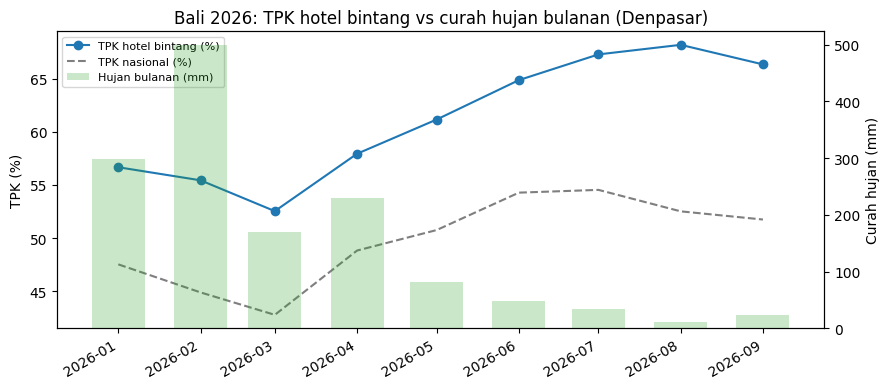

In [60]:
import matplotlib.pyplot as plt

VAR = ["tpk_persen", "hujan_total_mm", "tmax_rata2_c", "hari_hujan"]
panel = panel_final.copy()
for c in VAR:
    panel[c + "_dev"] = panel[c] - panel.groupby("provinsi")[c].transform("mean")

print("Korelasi Spearman, POOLED (38 provinsi x 9 bulan):")
display(panel[VAR].corr(method="spearman").round(2))
print("Korelasi Spearman, WITHIN-PROVINCE (selisih terhadap rata-rata provinsi):")
display(panel[[c + "_dev" for c in VAR]].corr(method="spearman").round(2))

# korelasi per provinsi (n = 9 bulan per provinsi → sangat tidak stabil, hanya untuk gambaran sebaran)
per_prov = pd.Series({p: g["tpk_persen"].corr(g["hujan_total_mm"], method="spearman") for p, g in panel.groupby("provinsi")})
print(f"Korelasi TPK~hujan per provinsi: median={per_prov.median():.2f}, "
      f"rentang {per_prov.min():.2f} s.d. {per_prov.max():.2f}, Bali={per_prov['BALI']:.2f}")

# --- Sorotan Bali ---
b = panel[panel.provinsi == "BALI"].sort_values("periode")
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(b["periode"], b["tpk_persen"], marker="o", color="tab:blue", label="TPK hotel bintang (%)")
ax1.plot(b["periode"], b["tpk_nasional_persen"], ls="--", color="tab:gray", label="TPK nasional (%)")
ax1.set_ylabel("TPK (%)")
ax2 = ax1.twinx()
ax2.bar(b["periode"], b["hujan_total_mm"], width=20, alpha=0.25, color="tab:green", label="Hujan bulanan (mm)")
ax2.set_ylabel("Curah hujan (mm)")
ax1.set_title("Bali 2026: TPK hotel bintang vs curah hujan bulanan (Denpasar)")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

In [61]:
import shutil
from google.colab import files

shutil.make_archive("data_akuisisi", "zip", "data")
files.download("data_akuisisi.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Catatan interpretasi (isi setelah menjalankan sel di atas)
Tulis temuan Anda dengan bahasa yang hati-hati. Hal yang perlu dipertimbangkan:

1. **Bandingkan pooled vs within-province.** Jika tandanya berbeda, bagian dari hubungan di pooled berasal dari perbedaan antar provinsi, bukan dari perubahan cuaca.
2. **n kecil.** Hanya 9 bulan per provinsi. Korelasi per provinsi sangat tidak stabil, jadi jangan menafsirkan angka tunggal Bali sebagai bukti.
3. **Musiman & kalender.** Libur sekolah, hari raya, dan musim liburan wisman terjadi bersamaan dengan musim kemarau/hujan. Cuaca tidak bisa dipisahkan dari faktor ini tanpa kontrol tambahan.
4. **Proxy cuaca.** Satu titik ibu kota (Denpasar untuk Bali) tidak sama dengan cuaca kawasan wisata (Ubud, Kuta, Nusa Dua, Kintamani). Data Open-Meteo adalah reanalisis, bukan stasiun.
5. **Bukan sebab-akibat.** Hasil di sini hanya asosiasi.
6. **Langkah lanjut yang masuk akal:** tambah titik cuaca di kawasan wisata Bali, tambah tahun-tahun sebelumnya (TPK historis BPS) agar bisa membandingkan bulan yang sama antar tahun, lalu kontrol musiman (mis. *fixed effect* bulan).